<a href="https://colab.research.google.com/github/joebathelt/UvA_MLM_fMRI/blob/main/MLM_fMRI_Week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction to Multi-Level Modelling**

# **Week 2 - Modelling Neural Computation**

Last week, you were introduced to modelling behavior in humans and in AI models. This week, you will get to learn the basics of artificial neural networks and apply them to modelling an object classification task. In the second part of the week, you will go one step lower and model the behavior of a single neuron and then extend that to model an entire cortical microcircuit


**Assessment**: This exercise is not graded. However, you will need to complete a quiz in the next session that tests your understanding of the topics covered in this tutorial. This includes your understanding of the concepts covered in this tutorial as well as the code implementation. Please refer to the example quiz on Canvas and read the learning objectives below for further guidance. The questions and sections marked [Optional] will not be tested in the quiz.


#### **Learning Objectives**
- The students understand the basic principles of artificial neural network models such as multi-layer perceptron (MLP) and deep convolutional neural networks (DCNNs).
- The students know how to build and train these models using PyTorch for the task of image classification
- The students can evaluate the performance of these models on a given dataset
- The students understand the concept of a convolutional kernel
- The students understand how to probe model behaviour by manipulating the architecture and data of a model
- The students understand the basics of a LIF and Izhikevich neuron model
- The students know how to drive the LIF neuron with external inputs, such as direct currents, and Gaussian white noise etc.
- The students have explored the parameters of the LIF and Izhikevich neuron models.
- The students have identified the different firing rate regimes of the Izhikevich neuron models.
- The students know how to model a cortical microcircuit using the brian2 simulator


The tutorials require a working knowledge of Python. If you happen to have never worked with python or want a refresher, you can work through [this notebook](https://colab.research.google.com/drive/1vof_tk3CZC4-GxQyO7sTNU4g3E0iKTr4?usp=sharing) (designed for a different course we teach).


**Credits**: Created by Abishek Thamma in 2026, based on original materials from Lynn Sörensen, Niklas Müller, Wieger Scheurer, and Jorge F. Mejias

The Part 2 setup and Sections 2.1-2.2 of this tutorial are based on *Neuromatch Academy*: Week 2, Day 3, Tutorial 1: `Real Neurons: The Leaky Integrate-and-Fire (LIF) Neuron Model`

_Neuromatch Academy Content creators:_ Qinglong Gu, Songtin Li, John Murray, Richard Naud, Arvind Kumar

_Neuromatch Academy Content reviewers:_  Maryam Vaziri-Pashkam, Ella Batty, Lorenzo Fontolan, Richard Gao, Matthew Krause, Spiros Chavlis, Michael Waskom, Ethan Cheng


## **Part 1 - Deep Convolutional Neural Networks**

#### **About this part**

In this part of the tutorial you will be introduced to one of the most commonly used computer vision approaches: Convolutional Neural Networks. You will begin this section with understanding the basics of how a simple neural network works. Following this, you will learn to build a simple deep neural network in PyTorch. You will learn to train this neural network to classify images on a dataset of clothing items. Next, you will move on to implementing and training a Convolutional Neural Network on a more complex dataset.

##### **Deep Learning**

Deep learning is a data science method that is often applied to problems where a task needs to be solved that would require a lot of repetitive human effort but that is still too complex in order to solve it with straightforward code. Examples of these problems are object classification or detection in images (also including medical images in e.g., tumor detection), language processing (including translation, sentiment analysis, and question answering), but also tasks like stock trading, image generation or fraud detection.

The basis in all these problem settings is constituted of three basic parts. 
- First, the problem needs to be defined as a specific task to solve, the so called objective function.
- Second, there needs to be a dataset on which this task needs to be solved. 
- Third, a model is needed that will attempt to solve the task on the given dataset.

In this tutorial, we will focus mostly on the dataset and the model part. We will generally ignore the wide varieties of objective functions that can be applied when using the same model or the same dataset, however we will still clearly define the task and objective function. 

<img src="https://cdn-images-1.medium.com/max/2000/1*ILJI87KKC7Y3y5ExxbGA8A.png" width="500">

<!-- <sub>https://cdn-images-1.medium.com/max/2000/1*ILJI87KKC7Y3y5ExxbGA8A.png<sub> -->


##### **PyTorch**

We will be using the [PyTorch](https://pytorch.org/) library, which is "an optimized tensor library for deep learning using GPUs and CPUs". Tensors are a data format that allow us to use the graphics processing unit (GPU).

#### **Setup**

This part trains neural networks, which is much faster on a GPU. Before running anything, switch to a GPU runtime: **Runtime → Change runtime type → T4 GPU**.

Then run the cell below to import the packages needed for this part.

In [ ]:
# Imports (Load packages that are needed)
import torch                              # PyTorch library for Tensors
from torch.utils.data import DataLoader
from torch import nn
import torchvision                        # Specialization of Torch for Computer vision
from torchvision import transforms

import os
import matplotlib.pyplot as plt           # Plotting library
import numpy as np                        # Numerical computations on CPU
from tqdm.notebook import tqdm            # Library to track progress of processes

### **Section 1.1 - Loading the dataset**



We will be using the MNIST fashion dataset, which is an image dataset inspired by the original MNIST dataset, which contains images of handwritten digits. The original is a historically important dataset as it perfectly illustrates the kind of problems that people wanted to outsource to AI systems. Imagine you would have to go through thousands of images of handwritten digits (think of post codes, marks in education, etc.) and document/digitize them into a database. However, due to rapid developments in machine learning, this handwritten digit 'problem' has become rather easy to solve. Hence, we'll make use of its slightly more challenging cousin: the fashion MNIST. This dataset contains 70.000 labeled grayscale images of clothing pieces (Zalando articles).

Before loading the dataset, we need to define the transformations that will be applied to each image in the dataset. This could be data augmentation, resizing of images and many other types of transformations. 

For this tutorial, we limit this to transforming the images to the format of tensors.

In [ ]:
transform_list = []
transform_list.append(transforms.ToTensor())
transform = transforms.Compose(transform_list)

Both the original and fashion MNIST dataset are publicly available through the torchvision package, which is the Computer Vision extension of PyTorch. We can download the dataset using the command below.

In [ ]:
mnist_fashion = torchvision.datasets.FashionMNIST('.', download=True, transform=transform)

Another feature of pytorch is the dataloader. Given any kind of dataset (i.e. a python class that implements a function returning an indexed item) the dataloader allows us to use multiple cores/CPUs in order to parallelize the loading of items (here, images) from the disk and also applies the above transformations (here, formatting as a tensor) such that we can directly use it on our GPU. The below command defines a dataloader using the fashion MNIST dataset that we just downloaded and loaded into this notebook. We want to use 8 cores in order to load 8 images from the disk at the same time. We also tell it the batch size, which is the number of images that it loads from the dataset in one iteration. All of these images will then be processed AT THE SAME TIME by the model when using a GPU. We can see why this would speed up the whole process a lot as compared to only being able to process a single image at the same time if we were to do this on a CPU instead.

In [ ]:
dataloader = DataLoader(dataset=mnist_fashion, batch_size=4096, num_workers=8)

We can then iterate over this dataloader (either by using the iter function together with the next function to get the next iteration, or using any loop).

As you can see, the dataloader does not only return an image but it also returns a corresponding label to the image. This label tells us what piece of clothing is present in the image. Using this pair of image and label we can directly define the task that we would want the model to solve: given the image as an input, output the type of clothing that is visible in the image. Before we will go into how to teach a model to do that, let's have a look at the actual images.

In [ ]:
img, label_no = next(iter(dataloader)) # Create an iterator of the dataloader and get the "next" iteration

In [ ]:
img.shape

Even though we only loaded one iteration of the dataloader, we got 4096 pairs of image and corresponding label numbers. This is the batch of items that we defined above that will be processed in parallel. We can also see that the images have a size of 28x28 pixels and that they have 1 channel, meaning that the images do not have color but are grayscale only. Let's visualize some of the images. If you execute the below cell multiple times, new random images will be plotted from the above batch.

Do you disagree with any of the labels? Are some images ambiguous?

In [ ]:
clothing_labels = list(mnist_fashion.class_to_idx.keys())

fig, ax = plt.subplots(1,8, figsize=(13, 5))

for ax_index, index in enumerate(np.random.randint(0, 4096, size=8)):

  ax[ax_index].imshow(transforms.ToPILImage()(img[index]), cmap='binary')
  ax[ax_index].set_title(clothing_labels[label_no[index]])
  ax[ax_index].axis('off')

plt.show()

> #### Question 1.1 - <font color='darkorange'><b>To Do</b></font>
>
> Take the code from above that specifies the transformations that should be applied for each image and modify it in the cell below. Insert transformations that:
> 1. Flip the image vertically.
> 2. Crop the image to 10x10 pixels
>
> Make edits in the cell below and plot the resulting images.

In [ ]:
transform_list = []

######## Your Code Here ########


################################

transform_list.append(transforms.ToTensor())
transform_augmented = transforms.Compose(transform_list)

mnist_augmented = torchvision.datasets.FashionMNIST(root='.', download=True, transform=transform_augmented)
dataloader_augmented = DataLoader(dataset=mnist_augmented, batch_size=4096, num_workers=8)

In [ ]:
img, label = next(iter(dataloader_augmented)) # Create an iterator of the dataloader and get the "next" iteration

In [ ]:
fig, ax = plt.subplots(1,8, figsize=(13, 5))

for ax_index, index in enumerate(np.random.randint(0, 4096, size=8)):
  ax[ax_index].imshow(transforms.ToPILImage()(img[index]), cmap='binary')
  ax[ax_index].set_title(clothing_labels[label_no[index]])
  ax[ax_index].axis('off')

plt.show()

print(f"Your images have these dimensions: {img[0].shape[1]}x{img[0].shape[2]}")

Now, that we have an idea of what the dataset looks like, and we have defined the problem that we would want to be solved, we can create a model that can help us solve this for us.

### **Section 1.2 - Modelling a simple neural network**



Before we get started on the convolutional neural networks, we will first implement a simple neural network (which in fact is not a "Deep" network yet) called Multi-Layer Perceptron or MLP.



The MLP is characterized by 4 core concepts.

The first is **nodes**. A node is the smallest unit of the network and computes a single function on some input. Each of the green dots in the below image is one such unit or node. Nodes either get the original data as input or more importantly, can get the *output* of another node as *input*. A function, often non-linear, is then computed on this input and the resulting output is either passed on to the next node or it constitutes the output of the entire model, e.g., a clothing label corresponding to an input image.

The second concept is a **layer**. In the image, we see that this particular MLP has three layers: an *input layer*, a *hidden layer*, and an *output layer*. Strikingly intuitive, the input layer receives the image as its input. Each node in the input layer receives the value of exactly one pixel of the image. In our case this means that we would have 28*28=784 nodes in the input layer. The number of nodes in the hidden layer can be arbitrarily specified by the user but crucially determines (to some extent) whether the model can solve the task at hand or not.

The last layer usually corresponds to the number of output options. In our case, there are 10 types of clothing labels, therefore the output layer would have 10 nodes. Each of these nodes represents one clothing label and outputs a value between 0 and 1 which will in turn be interpreted as the probability that that type of clothing is visible in the input image. So contrary to a common belief, the model does not output a single number directly telling us the index of our clothing label, but instead it outputs a probability for each label with which it "thinks" that that type of clothing is visible in its input image.


![link text](https://media.geeksforgeeks.org/wp-content/uploads/nodeNeural.jpg)

<sub>https://media.geeksforgeeks.org/wp-content/uploads/nodeNeural.jpg<sub>

The third concept is **scalability**. We already gathered that the particular MLP in our case would have 784 input nodes, some hidden nodes and 10 output nodes and therefore differs from the MLP instance that is shown in the image below. MLPs can come in any size. Interestingly, this is not only limited to the number of nodes per layer but also applies to the number of hidden layers. Every MLP also has one input layer and one output layer but everything in between is "arbitrarily" defined. This is commonly referred to as the "Black Box" when talking about Neural Networks, as it becomes harder and harder (up to impossible) to disentangle with what kind of behaviour the MLP model is solving the given task.

Below is a MLP that illustrates multiple hidden layers and also shows that each layer can have a different number of nodes.

![](https://www.researchgate.net/publication/354817375/figure/fig2/AS:1071622807097344@1632506195651/Multi-layer-perceptron-MLP-NN-basic-Architecture.jpg)

<sub>https://www.researchgate.net/publication/354817375/figure/fig2/AS:1071622807097344@1632506195651/Multi-layer-perceptron-MLP-NN-basic-Architecture.jpg<sub>


The last and likely most important concept is **learnability**. So far, we have talked about the input and output, the nodes and layers, and that all of that can be scaled up or down. But there are also connections between all the nodes. These symbolize the weights that are assigned between pairs of nodes. Weights are essentially real-valued numbers that are multiplied with the input in order to transform the input of an individual node to the desired output of that node.

We can see that for all the hidden layers, and the output layer in the two images above, the nodes have an arrow, i.e. a weight, coming from EVERY single node in the previous layer. So every node gets input from all nodes in the previous layer. If we imagine that the input is an image, then this means that each node in the (first) hidden layer has access to information from all nodes in the input layer and therefore to information from the WHOLE image. All of that information is then weighted by the values of the connections between the nodes after which a non-linear function, called activation function, is being applied. So a given node is computing the weighted sum of all its inputs (which is a linear computation) followed by a non-linear computation: its activation function.

![](https://www.researchgate.net/publication/354817375/figure/fig1/AS:1071622807117824@1632506195623/A-single-neuron-receiving-weighted-inputs.jpg)

<sub>https://www.researchgate.net/publication/354817375/figure/fig1/AS:1071622807117824@1632506195623/A-single-neuron-receiving-weighted-inputs.jpg<sub>


Often the Rectified Linear Unit (ReLU) or the Sigmoid function are used as activation functions.


![](https://miro.medium.com/v2/resize:fit:720/format:webp/1*XxxiA0jJvPrHEJHD4z893g.png)


<sub>https://miro.medium.com/v2/resize:fit:720/format:webp/1*XxxiA0jJvPrHEJHD4z893g.png<sub>


#### **Section 1.2.1 - Model Implementation**

This has been a long but needed explanation for how a typical MLP model looks like. We now have all the ingredients to build one using PyTorch.

Counterintuitively, a layer in PyTorch (or any other deep learning library) is rather defined as the set of weights instead of the set of nodes per layer. So a PyTorch layer will be defined in terms of the number of input nodes and the number of output nodes and the type of computation that is applied to the input. In our case we want that computation to be the weighted sum of inputs. This is called a Linear Layer. We want that to be followed by a ReLU operation as the non-linear activation function.

Our model requires 784 input nodes, one hidden layer with a high enough number of nodes and an output layer with 10 nodes.

> #### Question 1.2 - <font color='cornflowerblue'><b>To Think</b></font>
>
> Considering the function(ing) of neural networks such as the MLP, why do you think we use *non-linear* activation functions? Can you think of a type of non-linearity that is present in human neural information processing?

In [ ]:
class MLP(nn.Module):       # <- nn.Module builds the basis for any model
    def __init__(self, in_channels, out_channels, hidden_channels):
        super(MLP, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(in_channels, hidden_channels),  # Set of weights connecting the number of input nodes (defined by in_channels)
                                                      #       to the number of hidden nodes (defined by hidden_channels)
                                                      #       and the type of computation applied to them (weighted sum = Linear)
            nn.ReLU(),                                # Rectified Linear Unit - Activation function applied to every output (so the weighted sum of inputs) of the previous layer.
            nn.Linear(hidden_channels, out_channels)  # Same as above but now connecting the hidden layer to the output layer
        )


    # The forward function is called when the model receives an input X and defines how the model processes this input.
    # Here, the input is first flattened, going from 3-Dimensional to 1-Dimensional such that the number of pixels correspond to the number of input nodes.
    # Then, the input is fed through the network, meaning that all the weighted sums and activations are being applied and
    #     yielding an output telling us the probability for each of the possible digits on how likely that digit is visible in the image.
    def forward(self, x):
        # convert tensor (128, 1, 28, 28) --> (128, 1*28*28)
        x = x.view(x.size(0), -1)   # flatten
        x = self.layers(x)          # feed through network
        return x                    # return output

The above cell only defines the class that we can now create an instance of, specifying the exact number of nodes per layer. As said above, we need 28x28 = 784 input nodes and 10 output nodes. Additionally, we want the hidden layer to have 100 nodes.

In [ ]:
model = MLP(in_channels=28*28, hidden_channels=100, out_channels=10)

(Note that this model could already be used to execute the task. However, given that its parameters (i.e., the weights of each pair of nodes) are initialized randomly the model output would also be random.)

#### **Section 1.2.2 - Model Training**

Now, we want to change/tune the weights such that the model output corresponds to the label for the given input image. To do this, we need of course the image itself and the corresponding label.

Next, we need a measure of how well the model is doing. This is referred to as the loss function. This will tell us how close the output of the model is to the desired output. Remember, the model does not just output the clothing label itself but a probability distribution over all possible labels. If we conceptualize that the probability distribution of a single correct answer consists of all 0s and a single 1 for the node that corresponds to the correct label, we can imagine that we can compute the similarity between the model output distribution and the optimal distribution of probabilities.

The similarity between these two distribution is given by the CrossEntropyLoss. For a given pair of distributions or rather predicted labels and target/desired labels, it provides a single number output that reflects the degree to which the distributions match. Output numbers approximate 0 the better a predicted label matches the target label and become larger for a predicted label probability further away from the desired one (up to infinity).

Given this loss function, we can then calculate the gradient for each of the parameters of the model, i.e. the weights, and update these weights based on the direction of this gradient such that the loss would decrease if the model were to use the adjusted weights instead (a process called optimization). In the image below we see a simplification of the navigation through the geometry of the "loss landscape" during optimization. The y axis depicts the loss value, while the x and z axes represent general directions of the multi-dimensional weight space of the model.


<img src="https://miro.medium.com/v2/resize:fit:720/format:webp/0*c-RSa7ghwuBv-lWB" width="500">

<sub>https://miro.medium.com/v2/resize:fit:720/format:webp/0*c-RSa7ghwuBv-lWB<sub>

---

Altogether, this constitutes the following training paradigm:

1. Start with a pair of **input** (image) and corresponding **label** (clothing type)
2. Give the input to the model which feeds it through its layers and nodes and **outputs** a probability distribution over the possible outcomes.
3. Calculate the distance (or **loss**) between the model **output** and the **label** in terms of the CrossEntropyLoss function.
4. Calculate the **gradient** for each parameter/weight given the **loss**.
5. Update the model parameters/weights according to the **gradient**.
6. Repeat for a new pair of **input** and **label**.

In [ ]:
def train(model, loader, n_epochs, criterion, optimizer, device):
  model.train(True)

  for epoch in tqdm(range(n_epochs)):

    for item in tqdm(loader, leave=False):
      inputs, labels = item[0], item[1]       # Pair of input and corresponding label

      inputs = inputs.to(device)              # Move to desired device (always recommended to use GPU as calculation times drastically decreases for CPU use)
      labels = labels.to(device)              # Move to desired device (always recommended to use GPU as calculation times drastically decreases for CPU use)

      optimizer.zero_grad()                   # Set all gradient to 0, this is a technical step that is needed in order to only consider the gradients of this "round" of input-output-pairs and not the previous ones

      outputs = model(inputs)                 # Feed the input (image) through the model and get the probability distribution over targets (digits)

      loss = criterion(outputs, labels)       # Calculate the loss (distance or error) between outputs and labels using CrossEntropyLoss
      loss.backward()                         # Calculate the gradient for each parameter for the current loss

      optimizer.step()                        # Update each model parameter (weight) according to the calculated loss

> #### Question 1.3 - <font color='cornflowerblue'><b>To Think</b></font>
>
> Given the above code cell and the description of the training process, what is the role of *epochs* in the training process? Describe what an *epoch* constitutes and how it contributes to the concept of scalability.

Let's now define the remaining parts using PyTorch and then we can finally train our first model.

We need to choose a loss function to quantify the performance of our model, expressed as the match between our model predictions and the ground truth values, or rather the error of these predictions. For this, we will use the cross-entropy loss function. Furthermore, we need an optimizer: an algorithm to update our model parameters given its current performance. Specifically, we want to update these parameters in such way that they minimize the output of the loss function (and hence decrease prediction errors). For this we will choose the commonly used Adam optimizer. Other common optimizers are SGD (stochastic gradient descent), LBFGS or RMSProp. A list of available optimizers in PyTorch can be found [here](https://pytorch.org/docs/stable/optim.html#algorithms).

In [ ]:
criterion = torch.nn.CrossEntropyLoss() # Define loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # define optimizer, note that we have to tell the optimizer what parameters should be update. Here, we want all parameters to be updated
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # We define the GPU as the device that should be used during training, if a GPU is available. Note that everything said so far would also work on a CPU but would take much much longer

model = model.to(device) # Move the model to the desired device (GPU)

We have learned earlier that the model (using a GPU) can handle multiple pairs of input and output at the same time (which together are called a batch). So, we cut the whole dataset up into batches. We can now iterate over those batches such that the model sees each pair of input and label once. Unfortunately, showing each pair of input and label once will not enable the model to adjust its parameters such that it can perfectly classify all images correctly. Therefore, we need to show the whole dataset multiple times to the model in order for it to achieve a sufficient classification performance.

The below cell executes the train function that we defined above for a given model, loss function (criterion), optimizer and dataloader. We can further specify the device and the number of times the whole dataset is shown to the model (n_epochs). The cell below should finish after around 70 seconds for 10 epochs given the default model that we defined above. If you make changes to any if these parts, expect these times to differ.

Go ahead and train the model by executing the following cell:

In [ ]:
train(model=model, loader=dataloader, n_epochs=10, criterion=criterion, optimizer=optimizer, device=device)

#### **Section 1.2.3 - Model Testing**

To evaluate model performance we define a simple classification accuracy as the ratio of times the model assigned the highest probability to the actual target clothing label over the number of items in the dataset. For a given dataloader and model, the function below computes the just defined accuracy.

In [ ]:
def evaluate(loader, model, device):
    num_correct = 0
    num_samples = 0
    model.eval()


    with torch.no_grad():
        with tqdm(enumerate(loader), total=len(loader), desc='0/0') as t:
            for i, (item) in t:
                x, y = item[0], item[1]

                x = x.to(device=device)
                y = y.to(device=device)

                scores = model(x)

                ############################
                _, predictions = scores.max(1)
                ############################
                num_correct += (predictions == y).sum()
                num_samples += predictions.size(0)

                t.set_description(f'{num_correct}/{num_samples} correct ')

        accuracy = float(num_correct)/float(num_samples)
        print(f'Got {num_correct} \t/ {num_samples} correct -> accuracy {accuracy*100:.2f} %')

    return accuracy


> #### Question 1.4 - <font color='cornflowerblue'><b>To Think</b></font>
>
> Look at the line of code that is highlighted in the cell above:
>
> ```_, predictions = scores.max(1)```
>
> Interpret the code. Explain what the variables ```scores``` and ```predictions``` represent, respectively. What does the function ```scores.max(1)``` do, both programmatically (keep it simple) and conceptually with respect to the ```scores``` variable content.

Let's see how well our model is doing after it has been trained for 10 epochs:

In [ ]:
accuracy = evaluate(model=model, loader=dataloader, device=device)

We see that the model performs nearly perfectly after it has been trained for 10 epochs.

An important additional check that is commonly done in Machine Learning is to test the model on data that it has not seen during training. While this might seem unfair or task irrelevant, we need to remember that the initial solution that we were looking for is a model that can tell us for any image of a piece of clothing, what type of clothing it is. And for such a model to be able to work reliably and autonomously, we would want it to also be able to classify new pieces of clothing that it has never 'seen' before.

The easiest way to do this for any given dataset is to simply split it into two new datasets. One is called the training dataset and would consist of around 90% of the original data and will be used for training the model. The other is called the test dataset and consists of the remaining 10% of data. The test dataset is then used for so called inference, i.e. the model has to make its prediction but weights won't be change if the output is wrong. (Always ensure that the test dataset is not used for training the model or it will lead to "data leakage"!)

Many datasets, including fashion MNIST, have a pre-defined test dataset for the outlined purpose. The test dataset can be accessed and downloaded by setting the 'train' argument to false.

In [ ]:
fash_mnist_test = torchvision.datasets.FashionMNIST(root='.', download=True, transform=transform, train=False)

We can now assess/test the trained model's accuracy on this test dataset. Remember, this is data that the model has not seen before and could therefore not adjust its parameters to be able to predict the output class (clothing type) for these images.

We define a new dataloader for this test set and use the above 'evaluate' function to get the model's test performance in terms of classification accuracy.

In [ ]:
testloader = DataLoader(dataset=fash_mnist_test, batch_size=4096, num_workers=8)

In [ ]:
accuracy = evaluate(model=model, loader=testloader, device=device)

Impressively, the model is still able to predict almost all images correctly. Note that the fashion MNIST test set contains 10000 pairs of input and output.

But why the big hype around deep learning if a (non-deep) simple model that we can train in under 2 minutes can do this task so easily???


Well, despite the fashion MNIST being a more challenging alternative to the digit-based original MNIST, it also involves a task of classifying low resolution grayscale images into 10 distinct categories given thousands of training images. In order to illustrate a more timely problem, we will move on to a new dataset called CIFAR-10.

### **Section 1.3 - Training on a more complex dataset**



CIFAR-10 is a dataset that contains natural images, i.e. color images of actual object, more comparable to photographs. Each image has again assigned one of 10 labels. This time labels correspond to the object that is visible in the image. Let's first download the training and test datasets separately, then inspect the classes that the labels correspond to and then have a look at some of the images contained in this dataset.

(The below code is basically copied from above, while only changing the name of the dataset. Isn't that amazing how easy it is to download a new dataset using PyTorch?)

In [ ]:
cifar10 = torchvision.datasets.CIFAR10(root='.', transform=transform, download=True, train=True)
cifar10_test = torchvision.datasets.CIFAR10(root='.', transform=transform, download=True, train=False)

In [ ]:
cifar10.classes

In [ ]:
cifar_loader = DataLoader(dataset=cifar10, batch_size=4096, num_workers=8)
cifar_test_loader = DataLoader(dataset=cifar10_test, batch_size=4096, num_workers=8)

In [ ]:
img, label = next(iter(cifar_loader))

In [ ]:
img.shape

In [ ]:
fig, ax = plt.subplots(1,10, figsize=(20, 8))

for index in range(10):
  ax[index].imshow(transforms.ToPILImage()(img[index]), cmap='binary')
  ax[index].set_title(cifar10.classes[label[index].numpy()])
  if index > 0:
    ax[index].axis('off')

plt.show()

As you can see, the images are far more varied in their content. However, the resolution of images has increased only slightly, up to 32x32 pixels. Additionally, we are dealing with color images, so instead of one "color" channel (as is the case of grayscale images) we now have 3 color channels corresponding to RGB (red, green, blue).

Let's now apply the same model architecture that we use before in order to solve the new task: assign one of the 10 object classes to the given RGB images of objects.

We have to make some small alterations to the model because of the new dimensions of the dataset. The input layer now needs 3\*32\*32=3072 nodes as we will now flatten all 3 color channels and all pixels into one long list of values. We will keep the number of hidden nodes (channels) and output channels.

Further, we define again the CrossEntropyLoss as out criterion and we use the Adam optimizer, with the new model parameters (!).

In [ ]:
cifar_model = MLP(in_channels=3*32*32, hidden_channels=100, out_channels=10)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cifar_model.parameters(), lr=0.001)      # Note that we need to tell the optimizer which parameters it should use

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # We define the GPU as the device that should be used during training, if a GPU is available. Note that everything said so far would also work on a CPU but would take much much longer

cifar_model = cifar_model.to(device)

Let's see how well this model performs after 10 epochs of training. The execution of the below cell with the instructed parameters should take around 2 minutes (more parameters, longer training).

In [ ]:
train(model=cifar_model, loader=cifar_loader, criterion=criterion, n_epochs=10, optimizer=optimizer, device=device)

We again first evaluate the model on the training dataset to see whether it was able to learn the corresponding labels in the first place. If we are happy with the training classification accuracy, then we move on to test the model on the test dataset, to check whether it can also classify images that it hasn't seen during training.

In [ ]:
accuracy = evaluate(model=cifar_model, loader=cifar_loader, device=device)

After 10 epochs, the above model should have a training accuracy of around 40 %.

> #### Question 1.5 - <font color='darkorange'><b>To Do</b></font>
>
> Go ahead and run the train function for another 20 epochs. Once you finish training, also evaluate the model on the test set. Be aware that if we execute the cell in which the model is defined, this will reset the parameter to random again, so you would need to adjust the number of epochs to 30. Do not train the model for more than 30 epochs, instead continue with the tutorial :) 

In [ ]:
####### Your Code Here ######

As you can see, it seems very hard to increase the model's performance by purely training for longer. The model might not be "powerful" enough in order to solve this task. At this point, one could try to add more layers or more nodes in the hidden layer in order to allow the model more flexibility. However, in this case, the model would probably indeed achieve a higher classification accuracy on the training set but it would likely not be able to perform better on the test set. This is called overfitting and tells us that the model is learning the noise in the data (e.g. common background of objects on the same class: e.g., airplanes are more commonly photographed on a blue sky-like background) but it cannot transfer this to the test data where an airplane might occur standing at the airport (which is of course a totally realistic setting by which humans would not be confused). So it must be possible to change the network such that it learns what parts of the objects are indicative of its class label. This leads us to convolutions.

### **Section 1.4 - Convolutions to the rescue**


You may or may not know convolutions from other fields or mathematics. Generally speaking, a convolution expresses how the shape of one function is influenced by another. It can also be thought of as a kind of filtering using one function that corresponds to the filter and another function that corresponds to the signal that is to be filtered.

In computer vision a convolution is usually referred to as a feature or a kernel. This is, because the function that represents the filter/kernel/feature is a sort of prototype for a characteristic in the data as e.g., a straight line or a circle in an image. When a convolution that represents a straight line is being applied to a part of an image where a straight line is visible, this will yield the strongest output (defined by the mathematical computation behind the convolution which we will not inspect any closer here). When the same convolution is then applied to some other part where e.g. a circle is visible, this will yield a very weak output. In that sense, the output of a convolution reveals where and to what extent a certain feature or characteristic is present in an image.

To illustrate this, we can think back to how this would help in identifying the digit in a grayscale handwritten image. The handwritten 1,4 or 7 all have a lot of straight or diagonal lines while 3,6,8 or 0 all almost have no straight lines but more half-circles or circles. If we would apply the respective convolutions/kernel/features/filter to the handwritten digit images, we could easily learn something about the content of the images by just inspecting the distribution of occurrences of these features (lines and circles).

The kernel itself is defined as a two-dimensional matrix commonly with size of 3x3, 5x5 or 7x7 where each entry in the matrix is a learnable real number that can be adjusted. The below image illustrates how such a matrix can form kernels corresponding to different types of straight lines or edges.


<!-- ![](https://arxiv.org/html/2401.10178v1/extracted/5355876/Images/Randoms/Convmixer7.png) -->

![](https://media5.datahacker.rs/2018/10/multiplication_slicice.png)

<sub>https://media5.datahacker.rs/2018/10/multiplication_slicice.png<sub>

During training the weights of the kernels (i.e. the values in the matrix) will be adjusted such that the resulting activations allow the model to distinguish parts of the images from other parts of the image.

Another large advantage of using convolutions is that a single convolutional kernel, e.g., corresponding to a straight line, can be applied to every location in the image without needing more than one set of weights. In case of the MLP, remember that the input layer needed to have as many nodes as there were pixels in the image and nodes in the hidden layer received input from all previous nodes. Here, one convolutional kernel, of which there would still be many in a neural network model, can be applied to all locations of the image, no matter how many pixels there are without changing the number of weights.

> #### Question 1.6 - <font color='darkorange'><b>To Do</b></font>
>
> Implement the convolutional kernels from the above image and apply them to the data `content` below. How does the resulting output change when changing the kernels. Can you interpret these changes in terms of feature detection?

In [ ]:
from scipy.signal import fftconvolve

raise NotImplementedError('First kernel not implemented ...')
kernel_1 = np.array([ ... ])

kernel_2 = np.array([[1, 0, -1],
          [1, 0, -1],
          [1, 0, -1]])

raise NotImplementedError('Third kernel not implemented ...')
kernel_3 = np.array([ ... ])

content = np.array([
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, -1],
    [0, 0, 0, 1, 0, -1],
    [0, 0, 0, 1, 0, -1],
    [0, 0, 0, 0, 0, 0],
])

raise NotImplementedError('First convolution not implemented ...')
output_1 = ...

output_2 = fftconvolve(content, kernel_2)

raise NotImplementedError('First convolution not implemented ...')
output_3 = ...


# Let's plot the content, kernels and output
fig, ax = plt.subplots(4,2, figsize=(10, 8))

ax[0,0].imshow(content)
plt.delaxes(ax[0,1])

ax[0,0].set_title('Content')

ax[1,0].imshow(kernel_1)
ax[1,0].set_title('Kernel 1')
bar = ax[1, 1].imshow(output_1)
ax[1, 1].set_title('Output 1')

ax[2,0].imshow(kernel_2)
ax[2,0].set_title('Kernel 2')
bar = ax[2, 1].imshow(output_2)
ax[2, 1].set_title('Output 2')

ax[3,0].imshow(kernel_3)
ax[3,0].set_title('Kernel 3')
bar = ax[3, 1].imshow(output_3)
ax[3, 1].set_title('Output 3')


plt.tight_layout()
plt.show()

The next image showcases a selection of actual kernels from a trained convolutional neural network.

![](https://www.researchgate.net/profile/Nicola-Strisciuglio/publication/349727400/figure/fig3/AS:997110338027520@1614741038299/Visualization-of-the-convolutional-kernel-learned-in-the-first-layer-of-AlexNet.png)

<sub>https://www.researchgate.net/profile/Nicola-Strisciuglio/publication/349727400/figure/fig3/AS:997110338027520@1614741038299/Visualization-of-the-convolutional-kernel-learned-in-the-first-layer-of-AlexNet.png<sub>

> Note: these are kernels from the first layer of AlexNet (Krizhevsky et al., 2012) with a nowadays uncommon size of 11x11, but they work well for illustrative purposes.


### **Section 1.5 - Implementing a Convolutional Neural Network**



Let's implement a convolutional neural network given what we learned so far.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()

        ####################### THIS BLOCK DEFINES EACH INDIVIDUAL COMPONENT THAT WE WILL BELOW BRING INTO THE ORDER NEEDED

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)               # Convolutional Layer with 3 channels as inputs, 32 channels as outputs (so that means it has 32 kernels/filters) a kernel size of 3 and a padding of 1

        self.relu = nn.ReLU()                                                 # ReLU activation layer. Can be "reused" multiple times as there are no weights attached to this directly

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)    # Conv layer with 32 in and 64 out channels

        self.max_pool = nn.MaxPool2d(2, 2)                                    # Max Pooling layer, we can ignore how this works for now

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1)

        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)

        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1)

        self.fc1 = nn.Linear(256*4*4, 1024)                                   # Fully connected layer, needs flattening of the output of the previous layer which we will perform below
        self.fc2 = nn.Linear(1024, 512)                                       # Gradually decrease the number of nodes, down to the number of output classes
        self.fc3 = nn.Linear(512, 10)
        #######################


        ####################### Define the order of individual components with which the model should process the input
        self.layers = nn.Sequential(
            self.conv1,
            self.relu,
            self.conv2,
            self.relu,
            self.max_pool,  # output: 64 x 16 x 16

            self.conv3,
            self.relu,
            self.conv4,
            self.relu,
            self.max_pool,  # output: 128 x 8 x 8

            self.conv5,
            self.relu,
            self.conv6,
            self.relu,
            self.max_pool,  # output: 256 x 4 x 4

            nn.Flatten(),   # output: 256*4*4
            self.fc1,
            self.relu,
            self.fc2,
            self.relu,
            self.fc3
        )
        #######################


    ####################### The forward function defines what happens when the
    # model is called on an input x. In this case we just call the layers block,
    # with the predefined order of individual components
    # Note that we don't need to define the self.layers variable, but we can also
    # call each individual component on the input, which eventually just requires
    # a bit more writing. See a short example below

    def forward(self, x):
        return self.layers(x)

        ####################### actually equivalent to:
        # x = self.conv1(x)
        # x = self.relu(x)
        # x = self.conv2(x)
        # etc. ...
        # ...
        # x = self.fc3(x)
        # return x

Just like above, we need to create a new instance of the ConvNet model class, choose our loss function (criterion), the optimization algorithm (Adam), and the device to run the training on and train the model.

> #### Question 1.7 - <font color='darkorange'><b>To Do</b></font>
>
> Take the previous code for instantiating a model, now of the ConvNet class, create a new optimizer with the ConvNet parameters, and move the model instance to the GPU. Then, take the ```train``` and ```evaluate``` function and train the convolutional model for 20 epochs on the GPU on the train dataset. Afterwards, evaluate the trained model performance on the train dataset and also on the test dataset.

In [ ]:
####### Your Code Here #########


After evaluating the trained model on the test set, we see that using convolutions in a simple model increase test accuracy significantly. However, the model still does not perform perfectly. This is again due to the size of the model. A larger model (i.e., a model with more convolutional layer and more channels per layer) could perform even better. However, here we could probably also squeeze out some performance improvements by just training the model for a bit longer. Due to the lack of time we will not look further into this but rather resort to another class of models.

Before we move on, we want to have a closer look at what the above model actually learned. The cool thing about convolutions is that we can visualize the learned features/channels/kernels. Since every kernel is a two-dimensional matrix (as we have seen above), this matrix can be visualized. The below function takes a list of images and plots them in a grid of axes. No need to go through this code.

In [ ]:
def plot_images(images, fig=None, max_images: int = None, figsize=(15, 10), titles:list=None, cmap=None, axis_off:bool=True, orientation='landscape', custom_func_per_image=None):
    if max_images is None:
        max_images = len(images)

    if fig is None:
        fig = plt.figure(figsize=figsize)

    if orientation == 'landscape':
        n_rows = int(np.floor(np.sqrt(max_images)))
        n_cols = int(np.ceil(max_images / n_rows))
    else:
        n_cols = int(np.floor(np.sqrt(max_images)))
        n_rows = int(np.ceil(max_images / n_cols))

    index = 0
    for _ in range(n_rows):
        for _ in range(n_cols):
            if index >= max_images:
                break
            ax = fig.add_subplot(n_rows, n_cols, index+1)
            ax.imshow(images[index], cmap=cmap)
            if axis_off:
                ax.axis('off')
            if titles is not None and len(titles) > index:
                ax.set_title(titles[index])

            if custom_func_per_image is not None:
                custom_func_per_image(ax, index)
            index += 1

    fig.tight_layout()

    return fig

Let's pick one of the convolutional layer of the above model and visualize the trained kernels.

In [ ]:




conv_model = ... # Insert the reference to your model here (Or replace conv_model with the actual model instance below)
kernels = conv_model.conv4.parameters() # <- we can change conv4 to any of the other convolutional layers of the model #R
param_iter = next(iter(kernels))

In [ ]:
fig = plot_images([x[0,:,:].cpu().detach() for x in param_iter], cmap='gray')       # The '.cpu()' and '.detach()' move the kernels from the GPU to the CPU and thereby allow us to plot them

> #### Question 1.8 - <font color='darkorange'><b>To Do</b></font>
>
> Execute the above cell for different layers (conv1, conv3, conv6) and compare the kernel visualization. Can you find differences between layers? Can you identify kernels that have a certain structure (lines, circle, etc.)? Describe your findings.

### **Section 1.6 - Investigating model behaviour**


With time, it has become very clear *that* convolutional neural networks are good learners, but it remains obscure *how* they learn. The exact mechanistic underpinning of how a model behaves is called its 'black box' for a reason, but there are ways to carefully peek into this box (often referred to as AI transparency). One way of shedding empirical rays of light into this box is testing how model changes affect performance.

Neural networks are very malleable and can be kneaded into the optimal shape for its assigned purpose. While this flexibility is ideal for task optimization, it also allows us to explore the relative importance of various parameters. Each parameter value defines a different aspect of the way information is processed by a network. By manipulating specific parameter values, we can learn how the information processing aspect determined by that parameter relates to the way a model performs. For example, if the removal of a single convolutional layer results in a massive performance drop, this suggests that the model learns by means of hierarchical feature extraction.

We will once again make use of the fashion MNIST dataset. In this section of the tutorial, the goal is to build a number of alternative model classes that enable the investigation of different parameter changes.



Changes in model behaviour can be induced by making changes to one of the following factors:
- **Model architecture**
- **Training data**
- **Test data**

First, we're going to investigate the impact of architectural changes on model performance. Examples of parameters to manipulate are:
- Number of convolutional layers
- Kernel size
- Type of activation function
- In-/ exclude a batch normalisation layer
- In-/ exclude a dropout layer
- Stride, padding size
- Number of fully connected (dense) layers



> #### Question 1.9 - <font color='darkorange'><b>To Do</b></font>
>
> **Architectural changes**
>
> Create and train at least 2 new model class instances, where a specific parameter has been changed with respect to the original, vanilla ConvNet that we defined before (You will need to adjust the architecture a bit to account for the shape of the input). Examine their performance on the fashion MNIST classification task and report how the alteration of a specific parameter impacts model performance.
>
> Your answer should include:
> - The model alteration
> - Performance on the training and test set
> - Interpretation of these results
>
> The easiest way to report model performance by copying the outputs from the *evaluate()* function, as is done below:
>
> ```
> 54836/60000 correct : 100%
> 15/15 [00:11<00:00, 4.04it/s]
> Got 54836 / 60000 correct -> accuracy 91.39 %
>
> 9016/10000 correct : 100%
> 3/3 [00:01<00:00, 2.26it/s]
> Got 9016 / 10000 correct -> accuracy 90.16 %
> ```
>
> Optional: If relevant, also inspect what features the model has learned by inspecting the weights of your kernels/filters. For this you can make use of the *plot_images()* function we defined earlier on.

<details>
<summary>Stuck? Click to see how you can adapt the ConvNet architecture</summary>

```python
class FashionConvNet(nn.Module): # This is the standard model version we want to change
    def __init__(self):
        super().__init__()

        ####################### This block defines each individual component that we will use for our final model

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1) # Convolutional Layer with 1 channel as input (grayscale), 32 channels as outputs (so that means it has 32 kernels/filters) a kernel size of 3x3 and a padding of 1

        self.relu = nn.ReLU() # The non-linear activation function: Rectified Linear Unit (ReLU). Can be "reused" multiple times as there are no weights attached to this directly

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1) # Conv layer with 32 in and 64 out channels

        self.max_pool = nn.MaxPool2d(2, 2) # A max pooling layer, downsamples its input by providing the max value of a sliding pooling window

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1)

        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)

        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1)

        self.fc1 = nn.Linear(256*3*3, 1024)  # Fully connected layer, needs flattening of the output of the previous layer which we will perform below

        self.fc2 = nn.Linear(1024, 512)      # Gradually decrease the number of nodes, down to the number of output classes

        self.fc3 = nn.Linear(512, 10)

        ####################### Define the order of individual components with which the model should process the input
        self.layers = nn.Sequential(
            self.conv1,
            self.relu,
            self.conv2,
            self.relu,
            self.max_pool,  # output: 64 x 14 x 14

            self.conv3,
            self.relu,
            self.conv4,
            self.relu,
            self.max_pool,  # output: 128 x 7 x 7

            self.conv5,
            self.relu,
            self.conv6,
            self.relu,
            self.max_pool,  # output: 256 x 3 x 3

            nn.Flatten(),   # output: 256*3*3
            self.fc1,
            self.relu,
            self.fc2,
            self.relu,
            self.fc3
        )

    def forward(self, x):
        return self.layers(x)

```
</details>



Now, we're going to make the task more difficult. To this end, we will change the visual content of our test images.

By purposefully manipulating the input a model is given, we can investigate what information it uses as a basis for classification. For example, if you change the orientation of a t-shirt, can the model still classify it as accurately? or if a sweater has an ankle boot printed on it?

Neural networks are infamously talented in finding shortcuts to improve their task performance. For example, training a network to distinguish cows from camels with natural images will cause it to exploit background texture rather than learn the actual differences between the two species, as it is much easier to distinguish grass from sand. In this case you'll see near perfect classification accuracy in the training set, but terrible performance when tested with images of cows and camels in isolation, or in a non stereotypical environment.

This problem relates to the concept of **generalisation**. Although context is not at all trivial information for object recognition in humans, we are perfectly capable of distinguishing cows from camels outside their ordinary contexts, such as in a furniture store. Our knowledge of the world consists of more abstract conceptual representations that generalise to novel situations. As a result, we are very efficient at perceptual inference, even when information is scarce. To use neural networks for "twinning" purposes, it is important that models learn to represent information similar to the way humans do this. One way to investigate this, is by assessing the generalisability of a model's behaviour. We will do exactly this in the following questions.

> #### Question 1.10 - <font color='darkorange'><b>To Do</b></font>
>
> **Dataset changes**
>
> Create 2 new versions of the original test data subset in which the original image content is manipulated. This can for example be done by introducing noise, removing content, or applying filters. However, we encourage you to be as creative as possible and reflect on the implications of your changes in visual content with respect to the task at hand. Evaluate the generalisability of your models from Question 1.9 by comparing their performance at different test sets.
>
> Your answer should include:
> - An explanation and visual sample of your manipulated test images.
> - Performance on the manipulated test set (with respect to the original)
> - Interpretation of these results (how do different parameters relate to generalisability?)

In the first part of the tutorial, you learnt the basics of how to build a deep convolutional neural network for modelling a core aspect of human vision, object recognition. During this process, you learnt how to modify the architecture of the network and train and test it on different datasets. Lastly, you probed into the model's weights to get an idea of what the model has learnt to look for. 

In the second part of the tutorial, you will go one step lower. The previous sections, as you might have observed, represent an abstract notion of a neuron. In the following section, you will learn to model the function of actual individual neurons and use them to build a model of a cortical microcircuit.

## **Part 2 - Modelling at Neuronal Level**

#### **About this part**

In this part of the tutorial, we will first build a leaky integrate-and-fire (LIF) neuron model and study its dynamics in response to various types of inputs. Next, you will move on to implementing a more complex neuron model (the Izhikevich model). Lastly, you will move on to looking at more complex neural dynamics by implementing a cortical microcircuit.

#### **Setup**

Run the four cells below before starting this part.

In [ ]:
# @title Setup
!pip install brian2

In [ ]:
# @title General imports

# Imports
import numpy as np
import matplotlib.pyplot as plt


# import necessary libraries
import gc
import warnings

import matplotlib

# matplotlib.use(
#     "Agg"
# )  # Use 'Agg' backend for rendering plots in scripts or servers without GUI

from matplotlib import cm
import matplotlib.gridspec as gridspec

import pandas as pd
import scipy.stats as sc

from brian2 import *

warnings.filterwarnings("ignore")  # We are reckless!
import os

os.makedirs("spike_network", exist_ok=True)

In [ ]:
# @title Figure Settings
import ipywidgets as widgets  # interactive display
%config InlineBackend.figure_format = 'retina'
# use NMA plot style
plt.style.use("https://raw.githubusercontent.com/NeuromatchAcademy/course-content/master/nma.mplstyle")
my_layout = widgets.Layout()

In [ ]:
# @title Helper functions
def plot_volt_trace(pars, v, sp, unbound=False):
    """
    Plot trajectory of membrane potential for a single neuron

    Expects:
    pars   : parameter dictionary
    v      : volt trajectory
    sp     : spike train

    Returns:
    figure of the membrane potential trajectory for a single neuron
    """

    V_th = pars["V_th"]
    dt, range_t = pars["dt"], pars["range_t"]
    if sp.size:
        sp_num = (sp / dt).astype(int) - 1
        v[sp_num] += 20  # draw nicer spikes

    plt.plot(pars["range_t"], v, "b")
    plt.axhline(V_th, 0, 1, color="k", ls="--")
    plt.xlabel("Time (ms)")
    plt.ylabel("V (mV)")
    plt.legend(
        ["Membrane\npotential", r"Threshold V$_{\mathrm{th}}$"], loc=[1.05, 0.75]
    )
    if unbound == False:
        plt.ylim([-80, -40])


def plot_GWN(pars, I_GWN):
    """
    Args:
      pars  : parameter dictionary
      I_GWN : Gaussian white noise input

    Returns:
      figure of the gaussian white noise input
    """

    plt.figure(figsize=(12, 4))
    plt.subplot(121)
    plt.plot(pars["range_t"][::3], I_GWN[::3], "b")
    plt.xlabel("Time (ms)")
    plt.ylabel(r"$I_{GWN}$ (pA)")
    plt.subplot(122)
    plot_volt_trace(pars, v, sp)
    plt.tight_layout()




### **Section 2.1 - The Leaky Integrate-and-Fire (LIF) model**



#### **Section 2.1.1 - Basics of the LIF neuron model**

Now, it's your turn to implement one of the simplest mathematical model of a neuron: the leaky integrate-and-fire (LIF) model. The basic idea of LIF neuron was proposed in 1907 by Louis Édouard Lapicque, long before we understood the electrophysiology of a neuron (see a translation of [Lapicque's paper](https://pubmed.ncbi.nlm.nih.gov/17968583/) ). More details of the model can be found in the book [**Theoretical neuroscience**](http://www.gatsby.ucl.ac.uk/~dayan/book/) by Peter Dayan and Laurence F. Abbott.

The subthreshold membrane potential dynamics of a LIF neuron is described by

$$
C_m\frac{dV}{dt} = -g_L(V-E_L) + I,\quad (1)
$$

where $C_m$ is the membrane capacitance, $V$ is the membrane potential, $g_L$ is the leak conductance, $E_L$ is the resting potential, and $I$ is the external input current.

Dividing both sides of the above equation by $g_L$ gives

$$
\tau_m\frac{dV}{dt} = -(V-E_L) + \frac{I}{g_L}\,,\quad (2)
$$

where the $\tau_m$ is membrane time constant and is defined as $\tau_m=C_m/g_L$.

You might wonder why dividing capacitance by conductance gives units of time! Find out yourself why this is true.

To make it easier for us to implement this equation, we will also divide both sides by $\tau_m$, which gives

$$
\frac{dV}{dt} = (-(V-E_L) + \frac{I}{g_L}) * \frac{1}{\tau_m},\quad (3)
$$

Below, we will use Equation (3) to simulate the LIF neuron dynamics.

If $I$ is sufficiently strong such that $V$ reaches a certain threshold value $V_{\rm th}$, $V$ is reset to a reset potential $V_{\rm reset}< V_{\rm th}$, and voltage is clamped to $V_{\rm reset}$ for $\tau_{\rm ref}$ ms, mimicking the refractoriness of the neuron during an action potential:

$$
\mathrm{if}\quad V(t_{\text{sp}})\geq V_{\rm th}\;:\; V(t)=V_{\rm reset} \text{  for } t\in(t_{\text{sp}}, t_{\text{sp}} + \tau_{\text{ref}}]
$$
where $t_{\rm sp}$ is the spike time when $V(t)$ just exceeded $V_{\rm th}$.

Thus, the LIF model captures the facts that a neuron:
- performs spatial and temporal integration of synaptic inputs
- generates a spike when the voltage reaches a certain threshold
- goes refractory during the action potential
- has a leaky membrane

The LIF model assumes that the spatial and temporal integration of inputs is linear. Also, membrane potential dynamics close to the spike threshold are much slower in LIF neurons than in real neurons.


#### **Section 2.1.2 - Simulating the LIF neuron in Python**

We now write Python code to calculate Equation (3) and simulate the LIF neuron dynamics. As a background, this uses the Euler method to numerically integrate Equation (3).

The cell below initializes a dictionary that stores parameters of the LIF neuron model and the simulation scheme. You can use `pars=default_parameters_lif(T=simulation_time, dt=time_step)` to get the parameters (you can try to print the dictionary `pars`). Note that, `simulation_time` and `time_step` have the unit `ms`. In addition, you can add the value to a new parameter by `pars['New_param'] = value`.

In [ ]:
# @title

# @markdown Execute this code to initialize the default parameters. To see the parameters, double-click on this cell.

def default_parameters_lif(**kwargs):
  pars = {}

  # typical neuron parameters#
  pars['V_th'] = -55.     # spike threshold [mV]
  pars['V_reset'] = -75.  # reset potential [mV]
  pars['tau_m'] = 10.     # membrane time constant [ms]
  pars['g_L'] = 10.       # leak conductance [nS]
  pars['V_init'] = -75.   # initial potential [mV]
  pars['E_L'] = -75.      # leak reversal potential [mV]
  pars['tref'] = 2.       # refractory time (ms)

  # simulation parameters #
  pars['T'] = 400.  # Total duration of simulation [ms]
  pars['dt'] = .1   # Simulation time step [ms]

  # external parameters if any #
  for k in kwargs:
    pars[k] = kwargs[k]

  pars['range_t'] = np.arange(0, pars['T'], pars['dt'])  # Vector of discretized time points [ms]

  return pars


pars = default_parameters_lif()

The cell below defines the function to simulate the LIF neuron when receiving external current inputs. You can use `v, sp = run_LIF(pars, Iinj)` to get the membrane potential (`v`) and spike train (`sp`) given the dictionary `pars` and input current `Iinj`.

> #### Question 2.1 - <font color='darkorange'><b>To Do</b></font>
>
> In the code-cell below, complete the function!
>
> **Hint**: Use the third equation, the one with the membrane time constant.

In [ ]:
def run_LIF(pars, Iinj, stop=False):
  """
  Simulate the LIF dynamics with external input current

  Args:
    pars       : parameter dictionary
    Iinj       : input current [pA]. The injected current here can be a value
                 or an array
    stop       : boolean. If True, use a current pulse

  Returns:
    rec_v      : membrane potential
    rec_sp     : spike times
  """

  # Set parameters
  V_th, V_reset = pars['V_th'], pars['V_reset']
  tau_m, g_L = pars['tau_m'], pars['g_L']
  V_init, E_L = pars['V_init'], pars['E_L']
  dt, range_t = pars['dt'], pars['range_t']
  Lt = range_t.size
  tref = pars['tref']

  # Initialize voltage and current
  v = np.zeros(Lt)
  v[0] = V_init
  Iinj = Iinj * np.ones(Lt)
  if stop:  # set end of current to 0 if current pulse
    Iinj[:int(len(Iinj) / 4) ] = 0
    Iinj[-int(len(Iinj) / 4):] = 0
  tr = 0.  # the count for refractory duration

  # Simulate the LIF dynamics
  rec_spikes = []  # record spike times
  for it in range(Lt - 1):
    if tr > 0:  # check for refractoriness
      v[it] = V_reset
      tr = tr - 1
    elif v[it] >= V_th:  # reset voltage and record spike event
      rec_spikes.append(it)
      v[it] = V_reset
      tr = tref / dt

    ########################################################################
    ## TODO for students: compute the membrane potential v, spike train sp #
    # Fill out function and remove
    raise NotImplementedError('Student Exercise: calculate the dv/dt and the update step!')
    ########################################################################
    # calculate the increment of the membrane potential
    dv = ...

    # update the membrane potential
    v[it + 1] = ...

  rec_spikes = np.array(rec_spikes) * dt

  return v, rec_spikes


pars = default_parameters_lif(T=500)
# Uncomment below to test your function
# v, sp = run_LIF(pars, Iinj=100, stop=True)
# plot_volt_trace(pars, v, sp)
# plt.ylim([-80, -60])
# plt.show()

### **Section 2.2 - Response of an LIF model to different types of input currents**

In the following section, we will learn how to inject current to study the response of an LIF neuron.

#### **Section 2.2.1 - Direct current (DC)**

##### **LIF neuron driven by constant current**

First, we will look at the behavior of the LIF neuron under a constant DC input. Investigate the voltage response of the LIF neuron when receiving a DC input of 300 pA by `run_LIF` function.

In [ ]:
pars = default_parameters_lif(T=100)  # get the parameters

# Run the model to obtain v and sp
v, sp = run_LIF(pars, Iinj=300)

plot_volt_trace(pars, v, sp)
plt.show()

In the plot above, you see the membrane potential of an LIF neuron. You may notice that the neuron generates a spike. But this is just a cosmetic spike only for illustration purposes. In an LIF neuron, we only need to keep track of times when the neuron hit the threshold so the postsynaptic neurons can be informed of the spike.

##### **Parameter exploration of DC input amplitude (Interactive demo)**
Play around with the interactive demo below to see how the LIF neuron behavior changes for DC input with different amplitudes.

> #### Question 2.2 - <font color='darkorange'><b>To Do</b></font>
>
> How much DC is needed to reach the threshold (rheobase current)?

In [ ]:
# @title
# @markdown Make sure you execute this cell to enable the widget!
my_layout.width = '450px'
@widgets.interact(
    I_dc=widgets.FloatSlider(50., min=0., max=300., step=10.,
                               layout=my_layout),
    tau_m=widgets.FloatSlider(10., min=2., max=20., step=2.,
                                layout=my_layout)
)

def diff_DC(I_dc=200., tau_m=10.):
  pars = default_parameters_lif(T=100.)
  pars['tau_m'] = tau_m
  v, sp = run_LIF(pars, Iinj=I_dc)
  plot_volt_trace(pars, v, sp)
  plt.show()

> #### Question 2.3 - <font color='cornflowerblue'><b>To Think</b></font>
>
> How does the membrane time constant affect the frequency of the neuron?

#### **Section 2.2.2 - Gaussian white noise (GWN) current**

Given the noisy nature of neuronal activity _in vivo_, neurons usually receive complex, time-varying inputs.

To mimic this, we will now investigate the neuronal response when the LIF neuron receives Gaussian white noise $\xi(t)$ with mean

$$
E[\xi(t)]=\mu=0,
$$
Note that the GWN has zero mean, that is, it describes only the fluctuations of the input received by a neuron. We can thus modify our definition of GWN to have a nonzero mean value $\mu$ that equals the DC input, since this is the average input into the cell. The cell below defines the modified gaussian white noise currents with nonzero mean $\mu$.

In [ ]:
#@title
#@markdown Execute this cell to get function to generate GWN

def my_GWN(pars, mu, sig, myseed=False):
  """
  Function that generates Gaussian white noise input

  Args:
    pars       : parameter dictionary
    mu         : noise baseline (mean)
    sig        : noise amplitude (standard deviation)
    myseed     : random seed. int or boolean
                 the same seed will give the same
                 random number sequence

  Returns:
    I          : Gaussian white noise input
  """

  # Retrieve simulation parameters
  dt, range_t = pars['dt'], pars['range_t']
  Lt = range_t.size

  # set random seed
  # you can fix the seed of the random number generator so that the results
  # are reliable however, when you want to generate multiple realization
  # make sure that you change the seed for each new realization.
  if myseed:
      np.random.seed(seed=myseed)
  else:
      np.random.seed()

  # generate GWN
  # we divide here by 1000 to convert units to sec.
  I_gwn = mu + sig * np.random.randn(Lt) / np.sqrt(dt / 1000.)

  return I_gwn

##### **LIF neuron driven by GWN**

You can generate a noisy input with `my_GWN(pars, mu, sig, myseed=False)`. In the code block below, we set $\mu=250$ and $\sigma=5$. Note that fixing the value of the random seed (e.g., `myseed=2020`) will allow you to obtain the same result every time you run this.

> #### Question 2.4 - <font color='darkorange'><b>To Do</b></font>
>
> Complete the code below to simulate the LIF neuron with the generated GWN input 

In [ ]:
pars = default_parameters_lif(T=100.)
sig_gwn = 5.
mu_gwn = 250.
#######################################################
## TODO for students: compute the noisy input I_GWN   #
# and then compute v, sp with inject I_GWN into LIF   #
#######################################################

# Calculate the GWN current
# I_GWN = my_GWN(pars, ..., ..., myseed=2020)

# Run the model and calculate the v and the sp
# v, sp = run_LIF(pars, ...)

# Uncomment these lines after obtaining v, sp
# plot_GWN(pars, I_GWN)
# plt.show()

##### **Parameter explorer for noisy input (Interactive demo)**

As mentioned above, the mean of the GWN is the amplitude of DC. So indeed, when $\sigma = 0$, GWN is just a DC.

So the question arises how does $\sigma$ of the GWN affect the spiking behavior of the neuron.

> #### Question 2.5 - <font color='darkorange'><b>To Do</b></font>
>
> To get an intuition about this question you can use the following interactive demo that shows how the LIF neuron behavior changes for noisy input with different amplitudes (the mean $\mu$) and fluctuation sizes ($\sigma$).
>
> 1. how does the minimum input (i.e. $\mu$) needed to make a neuron spike change with increase in $\sigma$?
> 2. how does the spike regularity change with increase in $\sigma$?

In [ ]:
# @title

# @markdown Make sure you execute this cell to enable the widget!

my_layout.width = '450px'
@widgets.interact(
    mu_gwn=widgets.FloatSlider(200., min=100., max=300., step=5.,
                               layout=my_layout),
    sig_gwn=widgets.FloatSlider(2.5, min=0., max=5., step=.5,
                                layout=my_layout)
)


def diff_GWN_to_LIF(mu_gwn, sig_gwn):
  pars = default_parameters_lif(T=100.)
  I_GWN = my_GWN(pars, mu=mu_gwn, sig=sig_gwn)
  v, sp = run_LIF(pars, Iinj=I_GWN)
  plt.figure(figsize=(12, 4))
  plt.subplot(121)
  plt.plot(pars['range_t'][::3], I_GWN[::3], 'b')
  plt.xlabel('Time (ms)')
  plt.ylabel(r'$I_{GWN}$ (pA)')
  plt.subplot(122)
  plot_volt_trace(pars, v, sp)
  plt.tight_layout()
  plt.show()

#### **Section 2.2.3 - Firing rates and GWN**

Now that we learned to input different kinds of current to the LIF neuron and explored their effects, we can go one step further summarise the model's response to a range of inputs in a single plot. When we plot the output firing rate as a function of GWN mean or DC value, it is called the input-output transfer function of the neuron (or simply F-I curve).

##### **F-I explorer for different `sig_gwn` (Interactive demo)**
Here's an interactive demo that shows how the F-I curve of a LIF neuron changes for different levels of fluctuation $\sigma$.

> #### Question 2.6 - <font color='darkorange'><b>To Do</b></font>
>
> Play around with the $\sigma$ parameter.
>
> How does the F-I curve of the LIF neuron change as we increase the $\sigma$ of the GWN? We can already expect that the F-I curve will be stochastic and the results will vary from one trial to another. But will there be any other change compared to the F-I curve measured using DC?

In [ ]:
# @title

# @markdown Make sure you execute this cell to enable the widget!


my_layout.width = '450px'
@widgets.interact(
    sig_gwn=widgets.FloatSlider(3.0, min=0., max=6., step=0.5,
                                layout=my_layout)
)


def diff_std_affect_fI(sig_gwn):
  pars = default_parameters_lif(T=1000.)
  I_mean = np.arange(100., 400., 10.)
  spk_count = np.zeros(len(I_mean))
  spk_count_dc = np.zeros(len(I_mean))

  for idx in range(len(I_mean)):
      I_GWN = my_GWN(pars, mu=I_mean[idx], sig=sig_gwn, myseed=2020)
      v, rec_spikes = run_LIF(pars, Iinj=I_GWN)
      v_dc, rec_sp_dc = run_LIF(pars, Iinj=I_mean[idx])
      spk_count[idx] = len(rec_spikes)
      spk_count_dc[idx] = len(rec_sp_dc)

  # Plot the F-I curve i.e. Output firing rate as a function of input mean.
  plt.figure()
  plt.plot(I_mean, spk_count, 'k',
           label=r'$\sigma_{\mathrm{GWN}}=%.2f$' % sig_gwn)
  plt.plot(I_mean, spk_count_dc, 'k--', alpha=0.5, lw=4, dashes=(2, 2),
           label='DC input')
  plt.ylabel('Spike count')
  plt.xlabel('Average injected current (pA)')
  plt.legend(loc='best')
  plt.show()

#### **Section 2.2.4 - Revisiting ReLU**
In Part 1, you learned about deep learning and in particular, about deep convolutional neural networks (DCNN). In many aspects, DCNNs take inspiration from the brain and biological neurons. One of the tricks that are at the core of the success of deep learning is the use of non-linearities as activation functions. In fact, the activation functions currently used by deep learning were inspired by the models of biological neurons!

Below you can see the picture of a Rectified linear unit (ReLU), the most widely used activation function with DCNNs. If you compare this to the F-I curves we saw in Section 2.2.3, you might spot some similarities!

![ReLU](https://miro.medium.com/max/700/0*g9ypL5M3k-f7EW85.png)

> #### Question 2.7 - <font color='cornflowerblue'><b>To Think</b></font>
>
> Find one commonality and one difference between a ReLU and the F-I curves.

#### **Summary of the LIF model**

Congratulations! You've just built a leaky integrate-and-fire (LIF) neuron model from scratch, and studied its dynamics in response to various types of inputs, having:

- simulated the LIF neuron model

- driven the LIF neuron with external inputs, such as direct current, and Gaussian white noise

- studied how different inputs affect the LIF neuron's output firing rate.

In Section 2.3, we will be looking at a neuron model that can produce a more varied set of firing patterns, the Izhikevich model.

### **Section 2.3 - The Izhikevich model**



In Sections 2.1 and 2.2, we've learnt about the LIF model. The LIF is useful because it is relatively simple while explaining some of the neural data. It thus provides a useful abstraction from more complicated models such as the Hodgkin-Huxley model. The simplicity of the LIF model, however, also leads to a lack of neural dynamics - as you've seen in your simulations, it only produces very regular output patterns in the absence of noise.

Neuroscientific data suggests that there are different types of neurons in the brain and these types are typically identified based on their firing patterns (see figure below). In response to a steady current as we've used it in the previous examples, neurons can either be bursting or not, show adaptation or not. All of these more complex firing patterns and thus different neuron types cannot be captured with an LIF model.

In [2003](https://www.izhikevich.org/publications/spikes.pdf), Eugene Izhikevich introduced a model that could capture these different neural dynamics in a single model. Most importantly, this model was relatively simple (two equations and only four free parameters!) and computationally efficient ([Izhikevich, 2004](https://www.izhikevich.org/publications/whichmod.pdf)).

In this model, four parameters effectively determine the dynamics of the neuron. Returning to our example with the steady current, these four parameters determine what kind of behaviour would be observed in response to a steady current (see figure below).

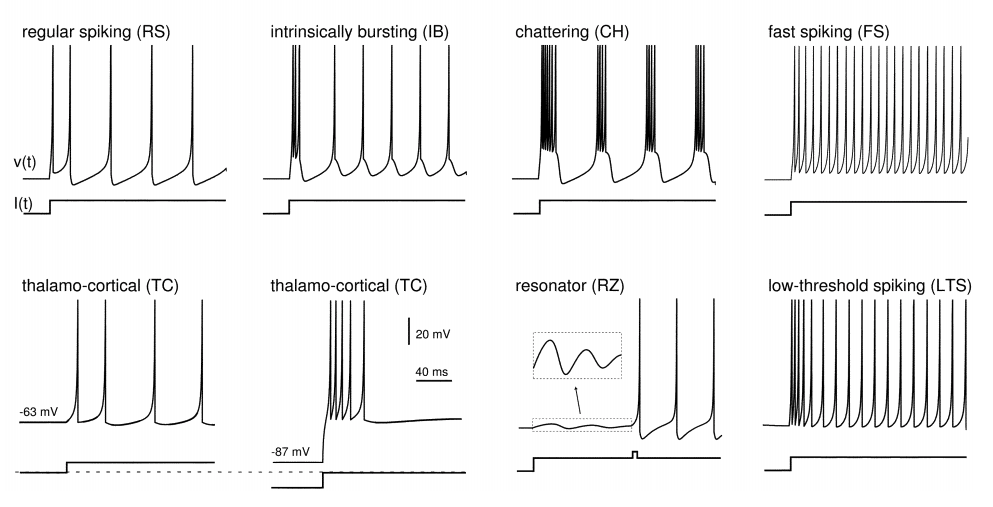

Figure is taken from [Izhikevich, 2003](https://www.izhikevich.org/publications/spikes.pdf)

#### **Section 2.3.1 - Basics of the Izhikevich neuron model**

As with the LIF model, you will now implement the Izhikevich model! The good news is that this model also does not consist of many equations.

The subthreshold membrane potential dynamics of an Izhikevich neuron is described by

$$
v' = 0.04v^2 + 5v + 140 -u + I, \quad (1)
$$

where $v$ is the membrane potential, $u$ represents the membrane recovery variable and $I$ is the external input current. $v$ is computed in $mV$ and at a time scale of $ms$.

The membrane recovery variable $u$ accounts for the activation of K+ ionic currents and inactivation of Na+ ionic currents. It also provides
negative feedback to the subthreshold membrane potential. It is described by

$$
u' = a(bv - u), \quad (2)
$$

where $a$ describes the time scale of the recovery variable $u$. Smaller values result in slower recovery. $b$ controls the sensitivity of the recovery variable $u$ to the subthreshold fluctuations of the membrane potential $v$. $u$ is also computed at a time scale of $ms$ but does not have a link to $mV$.

You might wonder about how the author came up with this set of equations. Have a look at the [paper](https://www.izhikevich.org/publications/spikes.pdf) to find out how this was derived!

If $I$ is sufficiently strong such that $v$ reaches the threshold value of 30 $mV$, $v$ and $u$ are reset and updated. Note that this is very similar to the LIF model! Thus,

$$
\mathrm{if}\quad v\geq 30 mV\;:\; v = c \text{  and }  u = u + d \quad (3)
$$

where $c$ describes the after-spike reset value of the membrane potential $v$ caused by the fast high-threshold K+ conductances and $d$ refers to the after-spike reset of the recovery variable $u$ caused by slow high-threshold Na+ and K+ conductances.

Thus, the Izhikevich model captures the fact that different types of neurons:
- vary in their time scale of recovering to baseline after a spike was emitted ($a$).
- vary in their sensitivity, that is, how prone a neuron is to emit a spike ($b$)
- vary in their reset value after emitting a spike ($c$)
- vary in their reset value of their membrane potential recovery variable ($d$).

<p align="center"><img src="https://people.ece.cornell.edu/land/PROJECTS/BioNB222section/StudentWork/aq23/FINAL/images/Izhikevich.jpg" alt="Parameter overview"></p>

Figure is taken from [Izhikevich, 2003](https://www.izhikevich.org/publications/spikes.pdf)


#### **Section 2.3.2 - Simulating the Izhikevich neuron in Python**

We now write Python code to calculate Equations (1)-(3) and simulate the Izhikevich neuron dynamics.

The cell below initializes a dictionary that stores parameters of the Izhikevich neuron model and the simulation scheme. You can use `pars=default_parameters_izhikevich(T=simulation_time, dt=time_step)` to get the parameters (you can try to print the dictionary `pars`). Note that, `simulation_time` and `time_step` have the unit `ms`. In addition, you can add the value to a new parameter by `pars['New_param'] = value`.

In [ ]:
# @title

# @markdown Execute this code to initialize the default parameters


def default_parameters_izhikevich(**kwargs):
  pars = {}

  # typical neuron parameters#
  pars['V_th'] = 30.     # spike threshold [mV]
  pars['a'] = 0.02  # parameter a, membrane recovery speed
  pars['b'] = 0.2     # parameter b, membrane recovery sensitivity
  pars['c'] = -65.       # parameter c, membrane potential reset [mV]
  pars['d'] = 8.       # parameter d, after spike reset of membrane recovery
  pars['V_init'] = -65.   # initial potential [mV]
  pars['U_init'] = pars['V_init'] * pars['b'] # initial membrane recovery
  pars['tau_m'] = 1 # model time step [ms]

  # simulation parameters #
  pars['T'] = 400.  # Total duration of simulation [ms]
  pars['dt'] = .1   # Simulation time step [ms]

  # external parameters if any #
  for k in kwargs:
    pars[k] = kwargs[k]

  pars['range_t'] = np.arange(0, pars['T'], pars['dt'])  # Vector of discretized time points [ms]

  return pars


pars = default_parameters_izhikevich()

The cell below defines the function to simulate the Izhikevich neuron when receiving external current inputs. You can use `v, sp = run_Izhikevich(pars, Iinj)` to get the membrane potential (`v`) and spike train (`sp`) given the dictionary `pars` and input current `Iinj`.

> #### Question 2.8 - <font color='darkorange'><b>To Do</b></font>
>
> In the code-cell below, complete the function!

In [ ]:
def run_Izhikevich(pars, Iinj, stop=False):
  """
  Simulate the Izhikevich dynamics with external input current

  Args:
    pars       : parameter dictionary
    Iinj       : input current (the injected current here can be a value)
                 or an array
    stop       : boolean. If True, use a current pulse

  Returns:
    rec_v      : membrane potential
    rec_sp     : spike times
  """
  # Set parameters
  v_th = pars['V_th']
  a, b, c, d = pars['a'], pars['b'], pars['c'], pars['d']
  v_init, u_init = pars['V_init'], pars['U_init']
  dt, range_t = pars['dt'], pars['range_t']
  Lt = range_t.size

  # Initialize membrane potential, membrane recovery and current
  v = np.zeros(Lt)
  u = np.zeros(Lt)
  v[0] = v_init
  u[0] = u_init
  Iinj = Iinj * np.ones(Lt)
  if stop:  # set end of current to 0 if current pulse
    Iinj[:int(len(Iinj) / 4) ] = 0
    Iinj[-int(len(Iinj) / 4):] = 0

  # Simulate the Izhikevich dynamics
  rec_spikes = []  # record spike times
  for it in range(Lt - 1):
    ########################################################################
    ## TODO for students: compute the membrane potential v, the membrane recovery u,
    # and the spike train sp
    # Fill out function and remove
    raise NotImplementedError('Student Exercise: calculate the membrane potential and the membrane recovery!')
    ########################################################################

    if v[it] >= v_th:  # reset voltage and record spike event
      rec_spikes.append(it)
      # Spike resets
      v[it] = ...
      u[it] = ...


    # update the membrane potential
    v[it + 1] = ...

    # update the membrane recovery
    u[it + 1] = ...

  rec_spikes = np.array(rec_spikes) * dt

  return v, u, rec_spikes


pars = default_parameters_izhikevich(T=400)
# Uncomment below to test your function
#v, u, sp = run_Izhikevich(pars, Iinj=10, stop=True)
#with plt.xkcd():
#  plot_volt_trace(pars, v, sp)
#  plt.ylim([-80, -30])
#  plt.show()

> #### [Optional] Question 2.9 - <font color='darkorange'><b>To Do</b></font>
>
> Make a plot of the membrane potential, the resting threshold and the membrane recovery!

In [ ]:
######### Your Code Here #######

> #### Question 2.10 - <font color='darkorange'><b>To Do</b></font>
>
> Make a model with the following parameters!
> * $a = 0.02$
> * $b = 0.2$
> * $c = -65$
> * $d = 0.25$
>
> Next, change the value of the DC input. For this set of parameters, what is the minimum DC current needed to trigger a spike (rheobase)?
>
> **Hint**: You can pass parameters to the default_parameters_izhikevich function like this `default_parameters_izhikevich(T=400)`

In [ ]:
######### Your Code Here #######

#### **Section 2.3.3 - Different neuron types and their dynamics**

The Izhikevich model can produce a wide range of dynamics as we've learnt above! In the next step, we are going to explore these diverse firing rate regimes in a bit more depth.



##### **Parameter exploration of the Izhikevich model (Interactive demo)**
Here's an interactive demo that shows how the model responses vary as a function of the four parameters $a,b,c$, and $d$, as well as with the input DC $I$.



In [ ]:
# @title
# @markdown Make sure you execute this cell to enable the widget!
my_layout.width = '450px'
@widgets.interact(
    I_dc=widgets.FloatSlider(10., min=0., max=50., step=5.,
                               layout=my_layout),
    a_param=widgets.FloatSlider(0.02, min=0., max=0.12, step=0.02,
                                layout=my_layout),
    b_param = widgets.FloatSlider(0.2, min=0.15, max=0.3, step=0.025,
                                layout=my_layout),
    c_param=widgets.FloatSlider(-50., min=-75., max=-45, step=1,
                                layout=my_layout),
    d_param=widgets.FloatSlider(2., min=0.05, max=9., step=0.05,
                                layout=my_layout)
)

def diff_DC(I_dc=200., a_param=0.02, b_param=0.2, c_param=-50., d_param=2.):
  pars = default_parameters_izhikevich(T=500., a=a_param, b=b_param, c=c_param, d=d_param)
  v, u, sp = run_Izhikevich(pars, Iinj=I_dc, stop=True)
  plot_volt_trace(pars, v, sp, unbound=True)
  plt.show()

> #### Question 2.11 - <font color='cornflowerblue'><b>To Think</b></font>
>
> Can you identify what firing pattern is produced by default in the widget above? If you have already changed the setting, simply executing the cell again, will reset it!

> #### Question 2.12 - <font color='cornflowerblue'><b>To Think</b></font>
>
> If you adjust the membrane potential reset, when does the model response transition to a different firing rate pattern? What other pattern does it transition to?

> #### [Optional] Question 2.13 - <font color='cornflowerblue'><b>To Think</b></font>
>
> If you adjust the membrane recovery reset, when does the model response transition to a different firing rate pattern? While doing this put the membrane potential reset back to -50. What other pattern does it transition to?

### **Section 2.4 - Modelling a cortical microcircuit**

In Sections 2.1 to 2.3, you learnt to build a simple LIF and an Izhikevich model from scratch, in pure Python. However, if we wish to model more complex neuronal dynamics, particularly at scale, the code complexity quickly increases.

Let us consider the case where we wish to model the dynamics of a cortical microcircuit (see figure below). To do this, we can use the help of a specialised package called brian2. brian2 abstracts away many low-level details, and allows us to easily build more complex network-level simulations. For instance, we can write the model equations as text, and brian2 can handle the numerical integration and spike detection.

#### **Section 2.4.1 - Building the network**

First, let's take a look at the illustration of the network we are going to simulate.

<center><img src="https://raw.githubusercontent.com/Beckinetic/SpikeNetwork/master/images/network_structure.gif" width=450></center>

*Note.* Excitatory neurons (triangles) and inhibitory neurons (circles) are shown. Excitatory connections (black) and inhibitory connections (grey) with >.04 connectivity probability are shown.

This network corresponds to a biological cortical network of the surface area of 1 mm$^2$. The network simulates 8 neuron populations: L2/3e (excitatory neurons in layer 2/3), L2/3i (inhibitory neurons in layer 2/3), L4e, L4i, L5e, L5i, L6e, L6i, and Th (thalamic neurons). The neurons in this network are connected with other neurons within the same layer or from other layers. This network also should be able to receive various forms external inputs so we can study the spontaneous and stimulus-evoked activities.

To build this cortical model, we have a rough three-step plan:

1. Define the single neuron model (LIF)
2. Wire up the neurons to form a network
3. Define the external input forms

We will be using the 'brian2' package to build this model. 

First, we will define the LIF neuron model in brian2.

> #### Question 2.14 - <font color='cornflowerblue'><b>To Think</b></font>
>
> But before we do that, do you think the LIF model as the model for single neurons in spiking network serves the right level of model simplification? (Hint: compare it with Hodgkin-Huxley neurons and convolutional neural network neurons)
>
> <center><img src="https://raw.githubusercontent.com/jeshraghian/snntorch/master/docs/_static/img/examples/tutorial2/2_1_neuronmodels.png"></center>

##### **LIF neurons recapped**

To recap, the core bit of the LIF model is the input integrating equation (linear differential equation of membrane voltage):

$${dv}/{dt} = (-( v- E_L ) + (I+I_{ext})/{g_L}) / {\tau_m}$$



Now we need to transform this equation into something interpretable to Python. Thanks to brian2, this process is very much simplified. We first assign values to several LIF parameters:

In [ ]:
def LIFparams():
    tau_m = 10.0 * ms  # membrane time constant
    tau_ref = 2.0 * ms  # absolute refractory period
    Cm = 250.0 * pF  # membrane capacity
    g_L = Cm / tau_m  # leak conductance
    E_L = -65.0 * mV  # leak reversal potential
    v_r = -65.0 * mV  # reset potential
    v_th = -50.0 * mV  # fixed firing threshold
    return tau_m, tau_ref, Cm, g_L, E_L, v_r, v_th


# Note. Using brian2, you can add SI units to the variables

Now let's try to write down the linear differential equation we've just seen with brian2. Note that you need to add the unit of the variable defined by the equation (in this case, volt) after a colon. And also in this particular case, you need to append `(unless refractory)` to the end of the equation. You may read more about brian2 usage in general [here](https://brian2.readthedocs.io/en/stable/resources/tutorials/1-intro-to-brian-neurons.html).

> #### Question 2.15 - <font color='darkorange'><b>To Do</b></font>
>
> Replace `###YOUR CODE HERE###` with the equation. (Remember to remove `raise NotImplementedError` after you inserted your code.)

In [ ]:
# Leaky integrate-and-fire model equations
# I: synaptic current
# tau_syn: synaptic time constant
# Iext: external current
LIFmodel = '''
	###YOUR CODE HERE###
	dI/dt = -I/tau_syn : amp
	Iext : amp
	'''
# Reset condition
resetLIF = '''
	v = v_r
	'''

raise NotImplementedError

So far we have defined the core passive membrane behavior pattern of a LIF neuron, and also how it handles external inputs. The firing threshold and refractory period length are fixed in our equation. That's basically everything we need for a single LIF neuron. We just need to set up some initial parameter values when we actually run it.

Now let's proceed to connecting those neurons.



##### **Balanced random network model**

The balanced random network model is what we are using to characterize the neuronal population dynamics. It receives external inputs (i.e., background inputs) and propagates the stimulation to the whole network through synapses. Previous studies provided valuable data of the population size and the connection probabilities, and we can build the network based on it. Let's take a look and run the network parameters.


> Connection probability: the probability that a neuron in the presynaptic population forms at least 1 synapse with a neuron in the postsynaptic population.



In [ ]:
###############################################################################
# Network parameters
###############################################################################
# Population size per layer
#          2/3e   2/3i   4e    4i    5e    5i    6e     6i    Th
n_layer = [20683, 5834, 21915, 5479, 4850, 1065, 14395, 2948, 902]

# Total cortical Population
N = sum(n_layer[:-1])

# Number of neurons accumulated
nn_cum = [0]
nn_cum.extend(cumsum(n_layer))

# Prob. connection table
#          From 2/3e    2/3i   4e     4i     5e     5i      6e     6i      Th        To
table = array([[0.101,  0.169, 0.044, 0.082, 0.032, 0.,     0.008, 0.,     0.    ], #2/3e
               [0.135,  0.137, 0.032, 0.052, 0.075, 0.,     0.004, 0.,     0.    ], #2/3i
               [0.008,  0.006, 0.050, 0.135, 0.007, 0.0003, 0.045, 0.,     0.0983], #4e
               [0.069,  0.003, 0.079, 0.160, 0.003, 0.,     0.106, 0.,     0.0619], #4i
               [0.100,  0.062, 0.051, 0.006, 0.083, 0.373,  0.020, 0.,     0.    ], #5e
               [0.055,  0.027, 0.026, 0.002, 0.060, 0.316,  0.009, 0.,     0.    ], #5i
               [0.016,  0.007, 0.021, 0.017, 0.057, 0.020,  0.040, 0.225,  0.0512], #6e
               [0.036,  0.001, 0.003, 0.001, 0.028, 0.008,  0.066, 0.144,  0.0196]])#6i

# Synapses parameters
d_ex = 1.5*ms      	# Excitatory delay
std_d_ex = 0.75*ms 	# Std. Excitatory delay
d_in = 0.80*ms      # Inhibitory delay
std_d_in = 0.4*ms  	# Std. Inhibitory delay
tau_syn = 0.5*ms    # Post-synaptic current time constant

# Layer-specific background input
bg_layer_specific = array([1600, 1500 ,2100, 1900, 2000, 1900, 2900, 2100])

# Layer-independent background input
bg_layer_independent = array([2000, 1850 ,2000, 1850, 2000, 1850, 2000, 1850])

We can see that the population size per layer, the connection probabilities, and the synapse parameters are already filled out. The connection table shows there might be recurrent intralayer connections (e.g., L2/3e -> L2/3e) and interlayer connections (e.g., L2/3e -> L4e). Note that every column shows the connections *from* the same presynaptic neurons, and every row shows the connection *to* the same postsynaptic neurons (the thalamic neurons can only serve as presynaptic neurons!).

You may also notice that there are layer-specific background inputs, which are external inputs to each layer and the numbers are estimated through experimental research. There are also layer-independent inputs, which have the identical number for every layer. The layer-independent inputs are used to test the robustness of this network. Actually, you may define the input array in various way to simulate different external input patterns.

> #### Question 2.16 - <font color='cornflowerblue'><b>To Think</b></font>
>
> The population size per layer is determined by anatomical studies. What is the approximate proportion of excitatory cells to inhibitory cells? What do you predict to happen in the network if we assign the same weight to synapses to inhibitory cells and synapses to excitatory cells?

With the population sizes, connection probabilities, and the synaptic data, we can wire up the neurons. In a balanced random network, every neuronal population forms connections to every other population, and the exact number of synapses in the connections is determined by the connection probability and population size. Once the synapse quantity has been settled, the synapses are randomly distributed to the neurons in the population.

Now we have the population sizes and the connection probabilities, then we can calculate the number of synapses by the following equation:

$$
C_a = 1 - (1 - \frac{1}{N^{pre}N^{post}})^K
$$

$C_a$ is the connection probability, $N^{pre}$ and $N^{post}$ denote the presynaptic and postsynaptic neuron numbers, and $K$ is the number of the synapses.

With a bit transformation, we obtain:

$$
K = \ln(1 - C_a) / \ln(1 - \frac{1}{N^{pre}N^{post}})
$$

> #### [Optional] Question 2.17 - <font color='cornflowerblue'><b>To Think</b></font>
>
> Try to derive the connection probability equation (Hint: think about the definition of connection probability).

Once we have number of the synapses between two populations, we can randomly assign the synapses to the neurons. It's time for some Python coding!

> #### Question 2.18 - <font color='darkorange'><b>To Do</b></font>
>
> Replace `###YOUR CODE HERE###` with the connection probability-synapse number equations. We use variable `nsyn` to denote the number of the synapses. Be aware, the number of synapses must be integers. 
>
> (Remember to remove `raise NotImplementedError` after you inserted your code)
>
> P.S We update the PDnet function below with additional code, ensure you add your code there too.

In [ ]:
def PDnet(NeuronGroup, stim, bg_type, w_ex, g, bg_freq, thal):
    # P and D are the initials of the authors of the paper

    w_ex = w_ex * pA  # excitatory synaptic weight
    std_w_ex = 0.1 * w_ex  # standard deviation weight

    pop = []  # Stores NeuronGroups, one for each population
    for r in range(0, 8):
        pop.append(NeuronGroup[nn_cum[r] : nn_cum[r + 1]])

    ###########################################################################
    # Creating synapse connections
    ###########################################################################

    syn_model = """
                w:amp			# synaptic weight
                """

    # equations executed only when presynaptic spike occurs:
    # for excitatory connections
    pre_eq = """
            I_post += w
            """

    con = []  # Stores connections

    ###########################################################################
    # Connecting neurons
    ###########################################################################
    pre_index = []  # presynaptic neuron index
    post_index = []  # postsynaptic neuron index

    # c: column (presynaptic neurons)
    # r: row (postsynaptic neurons)
    for c in range(0, 8):
        for r in range(0, 8):
            # number of synapses calculated with the original equation
            ###YOUR CODE HERE ###
            nsyn = ...
            raise NotImplementedError

            pre_index = randint(n_layer[c], size=nsyn)
            post_index = randint(n_layer[r], size=nsyn)

            # Assign weights to the synapses
            if nsyn < 1:
                pass
            else:
                # Excitatory connections
                if (c % 2) == 0:
                    # Synaptic weight from L4e to L2/3e is doubled as the data basis for these connections is not fully conclusive
                    if c == 2 and r == 0:
                        con.append(
                            Synapses(pop[c], pop[r], model=syn_model, on_pre=pre_eq)
                        )
                        con[-1].connect(i=pre_index, j=post_index)
                        con[
                            -1
                        ].w = "2.0*clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)"
                    else:
                        con.append(
                            Synapses(pop[c], pop[r], model=syn_model, on_pre=pre_eq)
                        )
                        con[-1].connect(i=pre_index, j=post_index)
                        con[-1].w = "clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)"
                    con[-1].delay = "clip(d_ex + std_d_ex*randn(), 0.1*ms, d_ex*inf)"

                # Inhibitory connections
                else:
                    con.append(Synapses(pop[c], pop[r], model=syn_model, on_pre=pre_eq))
                    con[-1].connect(i=pre_index, j=post_index)
                    con[-1].w = "-g*clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)"
                    con[-1].delay = "clip(d_in + std_d_in*randn(), 0.1*ms, d_in*inf)"

> #### Question 2.19 - <font color='cornflowerblue'><b>To Think</b></font>
>
> You may have noticed that every synapse has been assigned with a weight. The assignments to excitatory connections and inhibitory connections are a bit different:
> ```
> #Excitatory connections
> ...
> con[-1].w = 'clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)'
> ...
> # Inhibitory connections
> con[-1].w = '-g*clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)'
> ```
>
> The variable `g` is called inhibitory weight balance, and its default value in this tutorial is 4. Does the value remind you of something about the neuronal population size? Why do we balance the inhibitory weight?

The connections within the network are created, and there's one more thing we need to do: handling external inputs.

We have defined two types of background inputs
1. layer-specific: external inputs from grey matter, white matter, and thalamic (independent from the thalamic inputs we defined in the parameters) sources. The number is determined by empirical research.
2. layer-independent: also external inputs from grey and white matter. The number is set as identical for each layer.

You can look up the network parameters for the layer-specific and layer-independent numbers.

The reason for layer-independent is that the data basis for layer-specific inputs is actually limited. To rigorously test this network, we need to investigate the effects of other input parameterizations. We can also create other custom background types to do more testing.

We also model two types of inputs: poissonian and DC-current background inputs:

> Poissonian input: a type of stochastic or random input where the timing of incoming spikes follows a poisson process. This means the spikes arrive randomly but with a certain average rate. Poissonian input is used to simulate background synaptic noise.

> DC (direct current) input: a constant or fixed input current applied to the neuron. Unlike Poissonian input, it does not vary over time. This input is analogous to injecting a constant electrical current into a neuron. DC input is often used to simulate a constant external stimulus.


To simulate stimulus-evoked activity, we explicitly model the thalamic input to L4 and L6 by a thalamic population of 902 neurons (Peters and Payne 1993). You can find its own neuronal population and connection probabilities in the network parameters section. By defining the thalamic input this way, we can fine-tune the thalamic inputs towards specific neuronal populations.

Phew, we finally have everything for the network building! Now we just need to assemble the modules to create the complete network function. We also need to add a spike monitor to the network to collect the spiking data. 

(Don't forget to add your code here too and rerun the function again.)

In [ ]:
def PDnet(NeuronGroup, stim, bg_type, w_ex, g, bg_freq, thal):
    # P and D are the initials of the authors of the paper

    w_ex = w_ex * pA  # excitatory synaptic weight
    std_w_ex = 0.1 * w_ex  # standard deviation weight

    pop = []  # Stores NeuronGroups, one for each population
    for r in range(0, 8):
        pop.append(NeuronGroup[nn_cum[r] : nn_cum[r + 1]])

    ###########################################################################
    # Creating synapse connections
    ###########################################################################

    syn_model = """
                w:amp			# synaptic weight
                """

    # equations executed only when presynaptic spike occurs:
    # for excitatory connections
    pre_eq = """
            I_post += w
            """

    con = []  # Stores connections

    ###########################################################################
    # Connecting neurons
    ###########################################################################

    pre_index = []  # presynaptic neuron index
    post_index = []  # postsynaptic neuron index

    # c: column (presynaptic neurons)
    # r: row (postsynaptic neurons)
    for c in range(0, 8):
        for r in range(0, 8):
            # number of synapses calculated with the original equation
            ####### Your Code Here ##########
            nsyn = ...
            raise NotImplementedError
            pre_index = randint(n_layer[c], size=nsyn)
            post_index = randint(n_layer[r], size=nsyn)

            # assign weights to the synapses
            if nsyn < 1:
                pass
            else:
                # Excitatory connections
                if (c % 2) == 0:
                    # Synaptic weight from L4e to L2/3e is doubled
                    if c == 2 and r == 0:
                        con.append(
                            Synapses(pop[c], pop[r], model=syn_model, on_pre=pre_eq)
                        )
                        con[-1].connect(i=pre_index, j=post_index)
                        con[
                            -1
                        ].w = "2.0*clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)"
                    else:
                        con.append(
                            Synapses(pop[c], pop[r], model=syn_model, on_pre=pre_eq)
                        )
                        con[-1].connect(i=pre_index, j=post_index)
                        con[-1].w = "clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)"
                    con[-1].delay = "clip(d_ex + std_d_ex*randn(), 0.1*ms, d_ex*inf)"

                # Inhibitory connections
                else:
                    con.append(Synapses(pop[c], pop[r], model=syn_model, on_pre=pre_eq))
                    con[-1].connect(i=pre_index, j=post_index)
                    con[-1].w = "-g*clip((w_ex + std_w_ex*randn()),w_ex*0.0, w_ex*inf)"
                    con[-1].delay = "clip(d_in + std_d_in*randn(), 0.1*ms, d_in*inf)"

    ###########################################################################
    # Setting background input values
    ###########################################################################

    # Background number per layer
    if bg_type == 0:
        # layer-specific:
        bg_layer = bg_layer_specific
    elif bg_type == 1:
        # layer-independent:
        bg_layer = bg_layer_independent

    ###########################################################################
    # Creating poissonian and DC-current background inputs
    ###########################################################################
    bg_in = []
    if stim == 0:
        for r in range(0, 8):
            bg_in.append(
                PoissonInput(pop[r], "I", bg_layer[r], bg_freq * Hz, weight=w_ex)
            )

    # DC-current normalized by population
    if stim == 1:
        for r in range(0, 8):
            NeuronGroup.Iext[pop[r]] = 0.3512 * pA * bg_layer[r]

    ###########################################################################
    # Creating thalamic neurons as poissonian inputs
    ##########################################################################
    thal_con = []
    thal_input = []
    if thal == "ON":
        thal_input = PoissonGroup(
            n_layer[8], rates=120.0 * Hz
        )  # from PD paper: rates=15Hz
        for r in range(0, 8):
            thal_con.append(
                Synapses(thal_input, pop[r], model=syn_model, on_pre=pre_eq)
            )
            thal_con[-1].connect(p=table[r][8])
            thal_con[-1].w = 0.0

    ###########################################################################
    # Creating spike monitors
    ###########################################################################
    smon_net = SpikeMonitor(NeuronGroup)

    return pop, con, bg_in, smon_net, thal_input, thal_con

For the simulation, we still need to create a `runParams` function, so we can decide how long the simulation persists, the background input type, whether to turn on the thalamic inputs, etc. And we also need to use this function to add the LIF model definition to the network.

In [ ]:
def runParams(
    tsim=1.0,
    bg_type=0,
    stim=0,
    w_ex=87.8,
    g=4.0,
    bg_freq=8.0,
    thal="OFF",
    filename=None,
):

    ###########################################################################
    # Simulation parameters
    ###########################################################################
    defaultclock.dt = 0.1 * ms  # timestep of numerical integration method

    # neuron model
    eqs = LIFmodel
    reset = resetLIF
    tau_m, tau_ref, Cm, g_L, E_L, v_r, v_th = LIFparams()

    ###########################################################################
    # Creating neurons
    ###########################################################################
    neurons = NeuronGroup(
        N, eqs, threshold="v>v_th", reset=reset, method="linear", refractory=tau_ref
    )

    # seting initial values for membrane potential and currents
    neurons.v = "-58.0*mV + 10.0*mV*randn()"
    neurons.I = 0.0 * pA  # initial value for synaptic currents
    neurons.Iext = 0.0 * pA  # constant external current

    pop, con, bg_in, smon_net, thal_input, thal_con = PDnet(
        neurons, stim, bg_type, w_ex, g, bg_freq, thal
    )

    ###########################################################################
    # Running the simulation
    ###########################################################################
    net = Network(collect())

    if thal == "OFF":
        net.add(neurons, pop, con, bg_in)  # Adding objects to the simulation
        net.run(tsim * second, report="stdout")

    elif thal == "ON":
        w_thal = w_ex * pA  # excitatory synaptic weight from thalamus
        std_w_thal = w_thal * 0.1  # standard deviation weight
        net.add(
            neurons, pop, con, bg_in, thal_input, thal_con
        )  # Adding objects to the simulation

        for repeat in range(0, int(tsim)):
            net.run(0.7 * second, report="stdout")
            gc.collect()  # garbage collector to clean memory

            # Adding thalamic input
            for r in range(0, 8):
                thal_con[
                    r
                ].w = "clip((w_thal + std_w_thal*randn()),w_thal*0.0, w_thal*inf)"
            net.run(0.01 * second, report="stdout")
            gc.collect()  # garbage collector to clean memory

            # Removing thalamic input
            for r in range(0, 8):
                thal_con[r].w = 0
            net.run(0.29 * second, report="stdout")
            gc.collect()  # garbage collector to clean memory

    ###########################################################################
    # Saving raster plot
    ###########################################################################
    savetxt(filename, c_[smon_net.i, smon_net.t / ms], fmt="%i %.2f")

#### **Section 2.4.2 - Spontaneous activity**

##### **Simulation**

Given that we have built all the necessary components, we can now begin the network simulation! 

First, we start with the spontaneous activity where there is only background Poissonian inputs. But, before we do that, run the cell below to initialize some helper functions.

In [ ]:
# @title Helper Functions: Simulation General
def filename(g, bgrate, suffix=""):
    os.makedirs("data", exist_ok=True)

    return "data/data_raster_g" + str(g) + "_bgrate" + str(bgrate) + suffix + ".dat"


# default seed of pseudo random numbers to test reproducibility
s = 1000
seed(s)

*Note*. All the result data is stored in `/content/data`. And they are named using `g`, `bg`, and a custom suffix. Check the helper functions for naming rules.

In [ ]:
# run the spontaneous activity simulation

# it is recommended to simulate the network for 60 secs or longer, but since our
# class time is limited, we'll only simulate 1 sec, which may take ~2 min

# the initialization of the network may be slow due to unknown reasons,
# which may prolong the execution to ~10 min or even more. In case it is taking far too long, let me know

g = 4.0 # default value for inhibitory weight balance
bg = 8.0 # default value for background rate

bg_type = 0 # layer-specific inputs
stim = 0 # Poissonian inputs
tsim = 1 # time for simulation: 1 sec
runParams(tsim=tsim, bg_type=bg_type, stim=stim, filename=filename(g, bg, 'default'))
gc.collect() #garbage collector to clean memory

##### **Raster plot**

We can make a raster plot to showcase the spiking of neurons in the simulation time. Before plotting, the spiking data needs to be sampled and sorted.

In [ ]:
###############################################################################
# Defining plotting parameters
###############################################################################

# cortical layer labels: e for excitatory; i for inhibitory
lname = ['L23e', 'L23i', 'L4e', 'L4i', 'L5e', 'L5i','L6e', 'L6i']

# number of neurons by layer
n_layer_plot = [0, 20683, 5834, 21915, 5479, 4850, 1065, 14395, 2948];
l_bins = np.cumsum(n_layer_plot) # cumulative number of neurons by layer
N = np.sum(n_layer_plot)         # total number of neurons

# sampling parameters
psample = 0.025 # percentage of neurons by layer for the raster plot
n_sample = 1000 # number of neurons by layer for sampled measures

In [ ]:
def preprocess(tsim, filename, lname, n_layer_plot, l_bins, N, psample, n_sample):
    #############################################################################
    # Loading data and defining parameters
    #############################################################################
    data = pd.read_csv(filename, sep=" ", header=None, names=["i", "t"])

    # grouping spiking times for each neuron
    keys, values = data.sort_values(["i", "t"]).values.T
    ukeys, index = np.unique(keys, True)
    arrays = np.split(values, index[1:])

    spk_neuron = pd.DataFrame({"i": range(0, N), "t": [[]] * N})

    # DEPRECATED: List of arrays cannot be directly assigned to dataframe
    # spk_neuron.iloc[ukeys.astype(int),1] = arrays
    for neuron_index, spike_times in zip(ukeys.astype(int), arrays):
        spk_neuron.at[neuron_index, "t"] = spike_times.tolist()

    # creating a flag to identify cortical layers
    spk_neuron["layer"] = pd.cut(spk_neuron["i"], l_bins, labels=lname, right=False)
    data["layer"] = pd.cut(data["i"], l_bins, labels=lname, right=False)

    # sampling data:
    spk_neuron = spk_neuron.groupby(["layer"], observed=False).apply(
        lambda x: x.sample(n=n_sample)
    )

    # reset the index to remove the ambiguity
    spk_neuron = spk_neuron.reset_index(drop=True)

    # measures DataFrame to store firing rates, synchrony, and irregularity
    measures_layer = pd.DataFrame(index=lname)

    return spk_neuron, measures_layer, data

In [ ]:
spk_neuron, measures_layer, data = preprocess(tsim, filename(g, bg, 'default'), lname, n_layer_plot, l_bins, N, psample, n_sample)

In [ ]:
%matplotlib inline

def rasterplot(spk_neuron, tsim, lname, n_layer_plot, l_bins, N, psample, n_sample):
  ###############################################################################
  # Raster plot
  ###############################################################################
  plt.figure(figsize=(7.5,10))
  plt.gca().set_yticklabels([])
  acum_index = 0

  # graphs color codes: different colors for different layers
  dotsize = 2.5
  dotcolor = np.array([[0.0, 0.0, 255.0],
                      [102.0, 178.0, 255.0],
                      [255.0, 128.0, 0.0],
                      [255.0, 178.0, 102.0],
                      [0.0,   128.0, 0.0],
                      [153.0, 255.0, 153.0],
                      [255.0, 0.0,   0.0],
                      [255.0, 153.0, 153.0]])/255.0

  for i in range(len(lname)):
      index_start = l_bins[i]
      index_end = l_bins[i]+int(psample*n_layer_plot[i+1])

      x = data.t[data.i.isin(range(index_start,index_end))]
      y = data.i[data.i.isin(range(index_start,index_end))] + acum_index - index_start

      plt.plot(x/1000.0,y,'.',markersize=dotsize,color=dotcolor[i])

      # layers labels
      xpos = tsim-440/1000.0
      ypos = acum_index + (index_end-index_start)/2.0
      plt.text(xpos,ypos,lname[i],horizontalalignment='center', fontweight='bold')

      acum_index = acum_index + (index_end-index_start)

  plt.xlim(tsim-400/1000.0,tsim)
  plt.ylim(0,acum_index)
  plt.xlabel('time [s]')
  plt.ylabel(' ')
  plt.gca().invert_yaxis()
  plt.show()

In [ ]:
rasterplot(spk_neuron, tsim, lname, n_layer_plot, l_bins, N, psample, n_sample)

In this raster plot, we display the spiking per layer of 0.025 of the total neurons in the last 400 ms in our simulation.

> #### Question 2.20 - <font color='cornflowerblue'><b>To Think</b></font>
>
> What can you tell from this raster plot demonstrating the spontaneous activities of this networks? Does it align with [the figure in the original paper](https://academic.oup.com/view-large/figure/80937186/bhs35806.gif)?

The raster plot exhibits the different spiking behaviours across those layers. Other quantitative measures are also quite informative. We will plot the firing rate, irregularity, and synchrony of each neuron population.
> **Firing Rate**: the number of spikes a neuron generates per unit of time

> **Irregularity**: single-unit spike trains quantified by the coefficient of variation of the interspike intervals.

> **Synchrony**: multiunit spiking activity quantified by the variance of the spike count histogram (bin width 3 ms) divided by its mean (i.e., the Fano factor).

In [ ]:
%matplotlib inline


def firing_rate(spk_neuron, measures_layer, tsim):
    #############################################################################
    # Firing rates
    #############################################################################
    plt.figure(figsize=(7.5, 10))

    # graphs color codes: different colors for different layers
    dotsize = 2.5
    dotcolor = (
        np.array(
            [
                [0.0, 0.0, 255.0],
                [102.0, 178.0, 255.0],
                [255.0, 128.0, 0.0],
                [255.0, 178.0, 102.0],
                [0.0, 128.0, 0.0],
                [153.0, 255.0, 153.0],
                [255.0, 0.0, 0.0],
                [255.0, 153.0, 153.0],
            ]
        )
        / 255.0
    )

    freq = []
    freq = [float(len(spk_neuron.t[i])) / tsim for i in range(len(spk_neuron))]
    spk_neuron["f"] = freq

    measures_layer["f"] = spk_neuron.groupby(["layer"], observed=False)["f"].mean()

    # boxplot of firing rates by layer
    bplot = spk_neuron.boxplot(
        column="f",
        by="layer",
        showmeans=True,
        vert=False,
        rot=30,
        patch_artist=True,
        sym="+",
        return_type="dict",
        grid=False,
    )

    [
        bplot[0]["boxes"][i].set_facecolor(dotcolor[i])
        for i in range(0, len(bplot[0]["boxes"]))
    ]
    [
        bplot[0]["means"][i].set_markerfacecolor("white")
        for i in range(0, len(bplot[0]["boxes"]))
    ]
    [
        bplot[0]["means"][i].set_markeredgecolor("k")
        for i in range(0, len(bplot[0]["boxes"]))
    ]

    plt.title("")
    plt.ylabel("")
    plt.xlabel("firing rates[Hz]")
    plt.gca().invert_yaxis()
    plt.show()

In [ ]:
firing_rate(spk_neuron, measures_layer, tsim)

> #### Question 2.21 - <font color='darkorange'><b>To Do</b></font>
>
> Replace `##YOUR CODE HERE##` with your code to complete the irregularity plotting function.

In [ ]:
%matplotlib inline

def irregularity(spk_neuron, measures_layer):
  #############################################################################
  # Interspike intervals + coefficient of variation
  #############################################################################
  plt.figure(figsize=(7.5,10))

  # graphs color codes: different colors for different layers
  dotsize = 2.5
  dotcolor = np.array([[0.0, 0.0, 255.0],
                      [102.0, 178.0, 255.0],
                      [255.0, 128.0, 0.0],
                      [255.0, 178.0, 102.0],
                      [0.0,   128.0, 0.0],
                      [153.0, 255.0, 153.0],
                      [255.0, 0.0,   0.0],
                      [255.0, 153.0, 153.0]])/255.0

  # interspike intervals
  isi = []
  isi = ##YOUR CODE HERE##
  raise NotImplementedError()

  # coefficient of variation
  cv = []
  cv = ##YOUR CODE HERE##
  raise NotImplementedError()

  spk_neuron['cv'] = cv

  measures_layer['cv'] = spk_neuron.groupby(['layer'], observed=False)['cv'].mean()

  # barplot of mean CV
  plt.subplot2grid((3,2),(1,1))
  measures_layer['cv'].plot.barh(edgecolor='k' ,color=dotcolor, rot=30, width=0.8)
  plt.ylabel("")
  plt.xlabel('irregularity')
  plt.gca().invert_yaxis()
  plt.show()

In [ ]:
irregularity(spk_neuron, measures_layer)

In [ ]:
%matplotlib inline

def synchrony(spk_neuron, measures_layer):
  #############################################################################
  # Synchrony index
  #############################################################################
  plt.figure(figsize=(7.5,10))

  # graphs color codes: different colors for different layers
  dotsize = 2.5
  dotcolor = np.array([[0.0, 0.0, 255.0],
                      [102.0, 178.0, 255.0],
                      [255.0, 128.0, 0.0],
                      [255.0, 178.0, 102.0],
                      [0.0,   128.0, 0.0],
                      [153.0, 255.0, 153.0],
                      [255.0, 0.0,   0.0],
                      [255.0, 153.0, 153.0]])/255.0

  sync = []
  bins = np.arange(0,tsim*1000.0+3.0,3)

  for i in range(len(lname)):
      index_sample = spk_neuron.i[spk_neuron.layer.isin([lname[i]])]
      count, division = np.histogram(data.t[data.i.isin(index_sample)],bins=bins)
      sync.append(np.var(count[166:])/np.mean(count[166:]))

  measures_layer['sync'] = sync

  # barplot of synchrony index
  y_pos = np.arange(len(lname))
  plt.subplot2grid((3,2),(2,1))
  measures_layer['sync'].plot.barh(edgecolor='k' ,color=dotcolor, rot=30, width=0.8)
  plt.ylabel("")
  plt.xlabel('synchrony')
  plt.gca().invert_yaxis()
  plt.show()

In [ ]:
synchrony(spk_neuron, measures_layer)

Lastly, we will also plot the histogram to inspect the spiking distribution along the time axis.

In [ ]:
%matplotlib inline

def spike_histograms(spk_neuron, lname, tsim):
    #############################################################################
    # Spike count histograms for each layer
    #############################################################################
    n_layers = len(lname)

    fig, axes = plt.subplots(n_layers, 1, figsize=(7.5, 10))  # One subplot per layer

    bins = np.arange(0, tsim * 1000.0 + 3.0, 3)

    for i in range(len(lname)):
      index_sample = spk_neuron.i[spk_neuron.layer.isin([lname[i]])]
      count, division = np.histogram(data.t[data.i.isin(index_sample)],bins=bins)

      ax = axes[i]
      ax.bar(bins[167:], count[166:], width=3, color='blue', edgecolor='k')

      ax.set_title(lname[i])
      ax.set_xlabel("time")
      ax.set_ylabel("spike count")

    plt.tight_layout()
    plt.show()

In [ ]:
spike_histograms(spk_neuron, lname, tsim)

> #### Question 2.22 - <font color='cornflowerblue'><b>To Think</b></font>
>
> 1. Are the results in alignment with [the stimulation results in the paper](https://academic.oup.com/view-large/figure/80937186/bhs35806.gif)?
> 2. Are our simulated firing rates in agreement with [the experimental results](https://academic.oup.com/view-large/80937194)?
> 3. Compare firing rates of excitatory and inhibitory cells of different layers, which one is higher? What could be the neuroscience implications of it?
> 4. Does the network in general show asynchronous irregular (AI) firing behaviour? Consider the irregularity and synchrony data, and compare the raster plot with the following reference.
>
> <img src="https://raw.githubusercontent.com/Beckinetic/SpikeNetwork/master/images/behav_reference.jpg" width=450>
>
> (Brunel, 2000)

#### **Section 2.4.3 - In search of a good model**

In this section, we have built an entire cortical microcircuit from scratch using brian2 and studied its spontaneous activity. Standing on the shoulders of giants, one wonders: could this model be any better?

> #### Question 2.23 - <font color='cornflowerblue'><b>To Think</b></font>
>
> To evaluate the goodness of a neural model, what do you think that are the desiderata? List at least 3 criteria.

#### **Section 2.4.4: Final Reflections**

> #### Question 2.24 - <font color='cornflowerblue'><b>To Think</b></font>
>
> In Part 1, you started with a network whose weights were random, and through the process adjusted them step by step to reduce the loss on a classification task. 
> In Part 2, you started with the model equations and parameter values that were given to you, and used them to simulate activity.
>
> 1. Where did the parameter values come from in each case, and what changed them?
> 2. In Section 2.4, you changed the Izhikevich parameters yourself. How is that different from what you did with the CNN?
> 3. What kind of question about the brain can each type of model answer?